In [24]:
% pip install pandas
% pip install numpy
% pip install matplotlib
% pip install scikit-learn
% pip install progress
% pip install scikit-bio
 
% git clone https://github.com/RV2005/archetypes
% pip install "archetypes/"

UsageError: Line magic function `%` not found.


In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

from archetypes import AA
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset
import json

Couldn't import dot_parser, loading of dot files will not be possible.


## Performing AA

In [3]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"normalized_otu_Norm-sample_type.csv"
# otuFile = r"normalized_otu.csv"

otu = pd.read_csv(otuFile, index_col="sample")
# otu.drop("Unnamed: 0", axis=1, inplace=True)



NameError: name 'os' is not defined

In [ ]:
FRAC = 1
otu_sample = otu.sample(frac=FRAC)

In [ ]:
otu_log = otu_sample.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

In [ ]:
# from archetypes.numpy._aa_3 import AA_3
from archetypes import AA

AA_data = otu_log.to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 5
aa = AA(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)

print(aa.archetypes_)

[[3.57618913e-07 1.34697103e+00 1.31476442e-01 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.57650304e-07 1.11969198e-01 2.25303776e-04 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.04199175e+00 7.88235532e+00 1.50477665e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.58503305e-07 8.15965159e-02 7.35154486e-07 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [3.57625148e-07 3.36625456e+00 2.08700717e-02 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


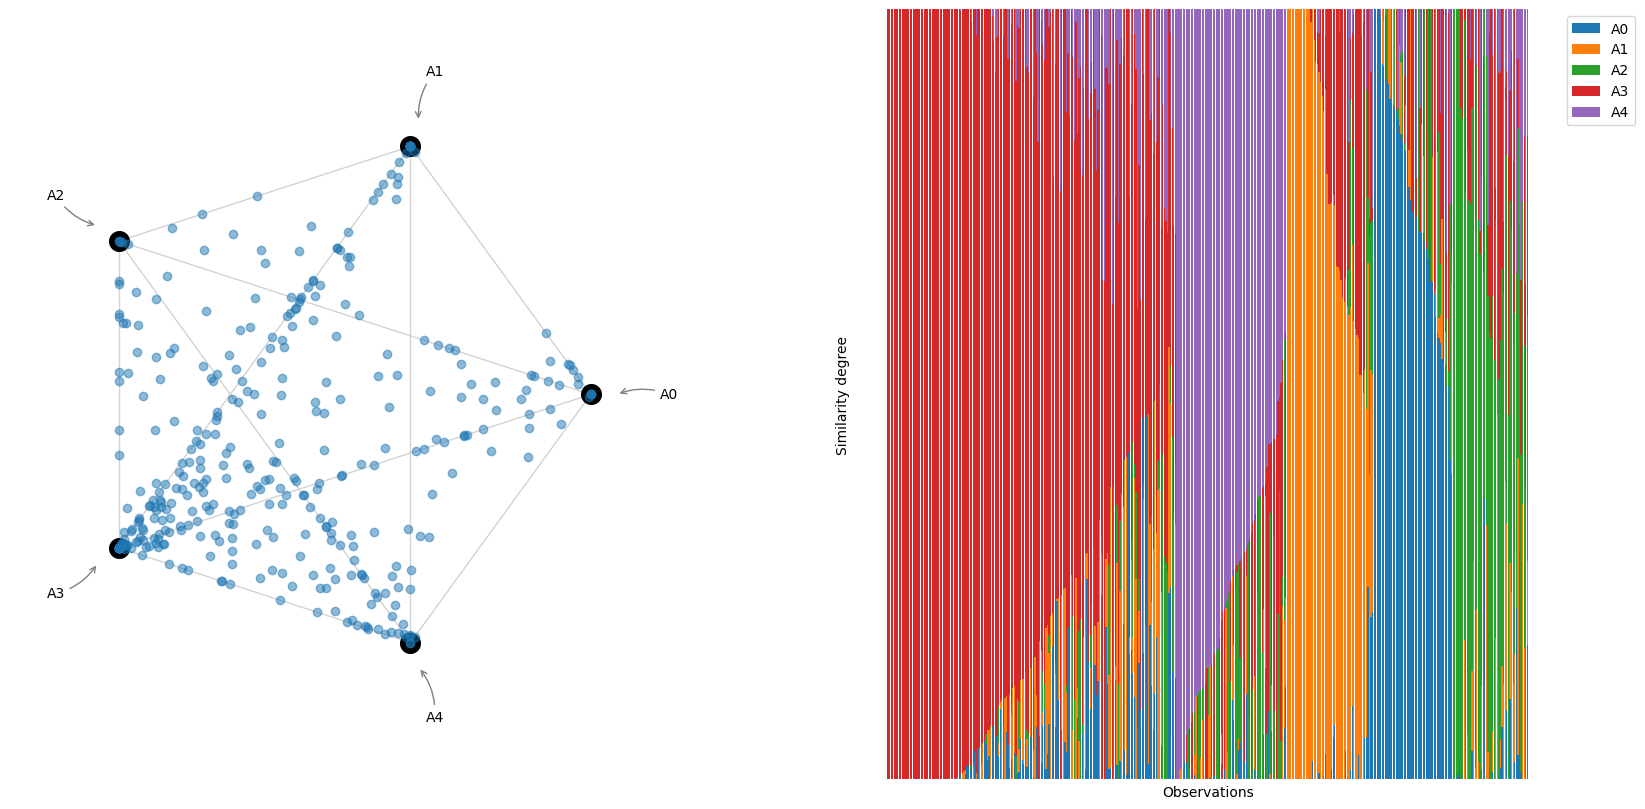

In [ ]:
data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

similarity_degree_permuted, _ = permute_dataset(aa.similarity_degree_, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


In [ ]:
# Make a json file containing all details for the archetypes
import json
aa_dict = {
    "archetypes": aa.archetypes_.tolist(),
    "similarity_degree": aa.similarity_degree_.tolist(),
    "labels": aa.labels_.tolist(), 
    "index": otu_log.index.tolist(),
    "columns": [f"Archetype {i+1}" for i in range(N_ARCHETYPES)], 
    "loss": aa.loss_,
    "info_perms": info["perms"][0].tolist(),
    "info_scores": info["scores"][0].tolist(),
    "info_alphas": info["alphas"][0].tolist(),
}


In [ ]:
methodName = method if isinstance(method, str) else "jensenshannon"

outName = f"otu_AA_{FRAC}_{group}_{methodName}.json"
outPath = os.path.join(outDir, outName)

json.dump(aa_dict, open(outPath, "w"))
# otu_aa.to_csv(outPath, sep="\t")

In [ ]:
json.dump(aa_dict, open("otu_AA_K5_norm_sample_type2.json", "w"))

## Standard Analysis

### Simplex Plotter Utility

In [2]:
### Simplex Plotter
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

def filter_further(data, further_filter, filter_type): 
    if filter_type == "equals": 
        return data[data.isin(further_filter)]
    elif filter_type == "not_equals":
        return data[~data.isin(further_filter)]
    elif filter_type == "greater_than":
        return data[data > further_filter]
    elif filter_type == "less_than":
        return data[data < further_filter]
    else: 
        return data


def plot_simplex(otu_aa, metadata, filter_cols, 
                cmap_name="tab20", legend_type="discrete", 
                remove_nan=False, further_filter=None, figsize=(15, 15), 
                remove_values=[], alpha=0.5, s=5, ax=None, legend_fontsize=12,
                verbose=False, custom_colors=None, **kwargs):
    """ 
    otu_aa: DataFrame
        The archetypal analysis data
    metadata: DataFrame
        The metadata
    filter_cols: list
        The columns to filter the data by (must contain exact column names from metadata)
    cmap_name: str (optional)
        The name of the colormap to use
    legend_type: str (optional)
        The type of legend to use. Can be "discrete" or "continuous"
    remove_nan: bool (optional)
        Whether to remove NaN values from the data
    further_filter: Dict (optional) = {"filter_type": "equals", "value": []}
        Further filter the data by the values in this list
    figsize: tuple (optional)
        The size of the figure
    custom_colors: dict (optional)
        A dictionary of custom colors to use for the legend. Keys are the labels, values are the color ints/floats on cmap.
    """

    present_idx = otu_aa.index.intersection(metadata.index)
    present_points = otu_aa.loc[present_idx]

    # Print the number of values dropped
    if verbose:
        print(f"Dropped {len(otu_aa) - len(present_points)} data points: Index not found in metadata")

    # For each data point, add the first non-null value from filter_cols to the filter_labels
    filter_labels = pd.Series(index=present_points.index, dtype=str)
    for col in filter_cols:
        filter_labels = filter_labels.fillna(metadata.loc[present_idx, col])

    # If further_filter is not none, filter the dataset by matching values to each further_filter element
    if further_filter is not None:
        present_points = filter_further(present_points, further_filter["filter_type"], further_filter["value"])
        filter_labels = filter_further(filter_labels, further_filter["filter_type"], further_filter["value"])

    if remove_nan:
        nan_idx = filter_labels.index[filter_labels.isnull()]
        present_points = present_points.drop(nan_idx)
        filter_labels = filter_labels.drop(nan_idx)

    if(len(remove_values) > 0):
        for col, value in remove_values.items():
            rem_idx = filter_labels.index[filter_labels == value]
            present_points = present_points.drop(rem_idx)
            filter_labels = filter_labels.drop(rem_idx)


    if(legend_type == "discrete"):
        if custom_colors is not None:
            unique_colors = {c: custom_colors[c] if c in custom_colors else i for i, c in enumerate(filter_labels.unique())}
        else:
            unique_colors = {c: i for i, c in enumerate(sorted(filter_labels.unique(), reverse=True))}
        color = filter_labels.map(unique_colors)
    elif(legend_type == "continuous"):
        unique_colors = filter_labels
        color = filter_labels.astype(float)

    cmap = plt.get_cmap(cmap_name, len(unique_colors))

    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=figsize)
        
#     MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
    cmap = plt.get_cmap(cmap_name, len(unique_colors))
    simplex(present_points, alpha=alpha, ax=ax, c=color, cmap = cmap, s=s, vertices_labels=otu_aa.columns, **kwargs)

    def add_discrete_legend(ax, unique_colors, cmap):
        legend_patches = [
            Patch(color=cmap(unique_colors[c]), label=c)
            for c in unique_colors
        ]

        # Add the legend to the plot
        ax.legend(handles=legend_patches, title=filter_cols, loc='upper right', fontsize=legend_fontsize, bbox_to_anchor=(1.2, 1))


    def add_continuous_legend(ax, filter_labels, cmap):
        # Add the legend to the plot with appropriate min and max values
        cbar = plt.colorbar(ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
        cbar.set_label(f"{filter_cols}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )

    if legend_type == "discrete":
        add_discrete_legend(ax, unique_colors, cmap)
    elif legend_type == "continuous":
        add_continuous_legend(ax, filter_labels, cmap)




### Compendium Extraction

In [3]:
PROJECT_DATA_COLS = ['link', 'amplicon', 'avg_length', 'bead_beating', 'kit', 'sample_type','condition', 'subjects', 'notes']
SAMPLE_METADATA_COLS = ['project', 'srr', 'library_strategy', 'library_source', 'pubdate','total_bases', 'instrument', 'geo_loc_name', 'iso', 'region']

def extract_metadata_compendium(index, tags, sample_meta, projects, extract_cols = [], verbose=False):
    
    project_cols = [col for col in extract_cols if col in projects.columns]
    sample_cols =  [col for col in extract_cols if col in sample_meta.columns]
    tags_cols =    [col for col in extract_cols if col not in project_cols and col not in sample_cols]

    metadata = pd.DataFrame(index=index, columns=extract_cols)
    for col in project_cols:
        metadata[col] = metadata.index.map(lambda x: projects.loc[x.split("_")[0], col])
        
    if "project" in sample_meta.columns and "srr" in sample_meta.columns:    
        sample_meta["sample"] = sample_meta["project"] + "_" + sample_meta["srr"]
        sample_meta.set_index("sample", inplace=True)
        
    for col in sample_cols:
        metadata[col] = sample_meta[col]
        
    for col in tags_cols:
        col_tags_df = tags[tags["tag"] == col]
        col_tags_df["sample"] = col_tags_df["project"] + "_" + col_tags_df["srr"]
        col_tags_df.set_index("sample", inplace=True)
        metadata[col] = col_tags_df["value"]

    return metadata


### Loading the results
Change the paths below according to your file structure

In [4]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region30k\otu_AA_K7_1.0_None_jensenshannon.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)


In [7]:
projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")

# projects = pd.DataFrame()
# meta = pd.read_table(r"datasets\tsv\hadza_meta_formatted.tsv", index_col=0)
# tags = pd.DataFrame()

### Plotting the Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1701354116.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

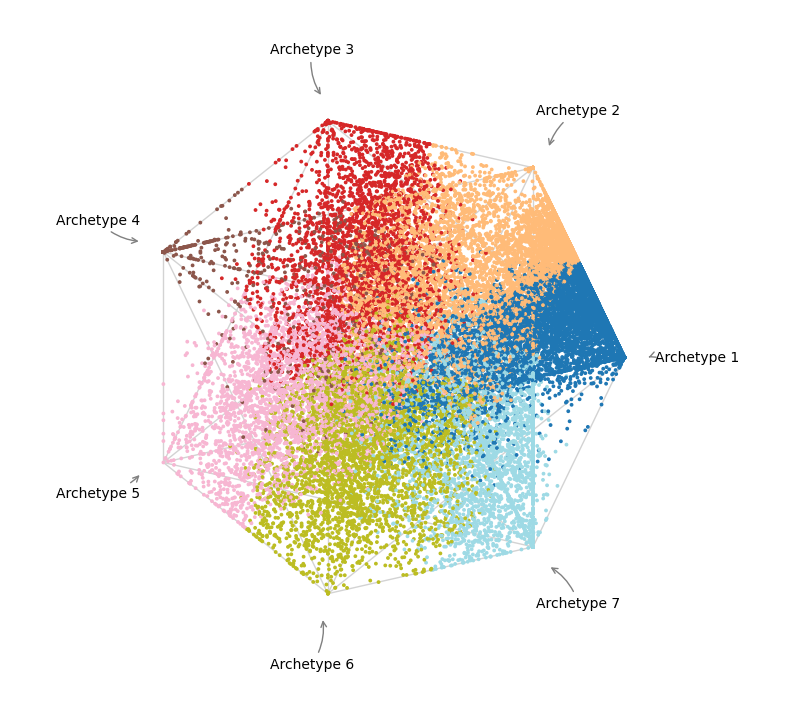

In [6]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=1, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [9]:
otu_aa_swapped = otu_aa[[ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]]
# otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 3", "Archetype 5", "Archetype 6", "Archetype 2" , "Archetype 4"]]

### Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

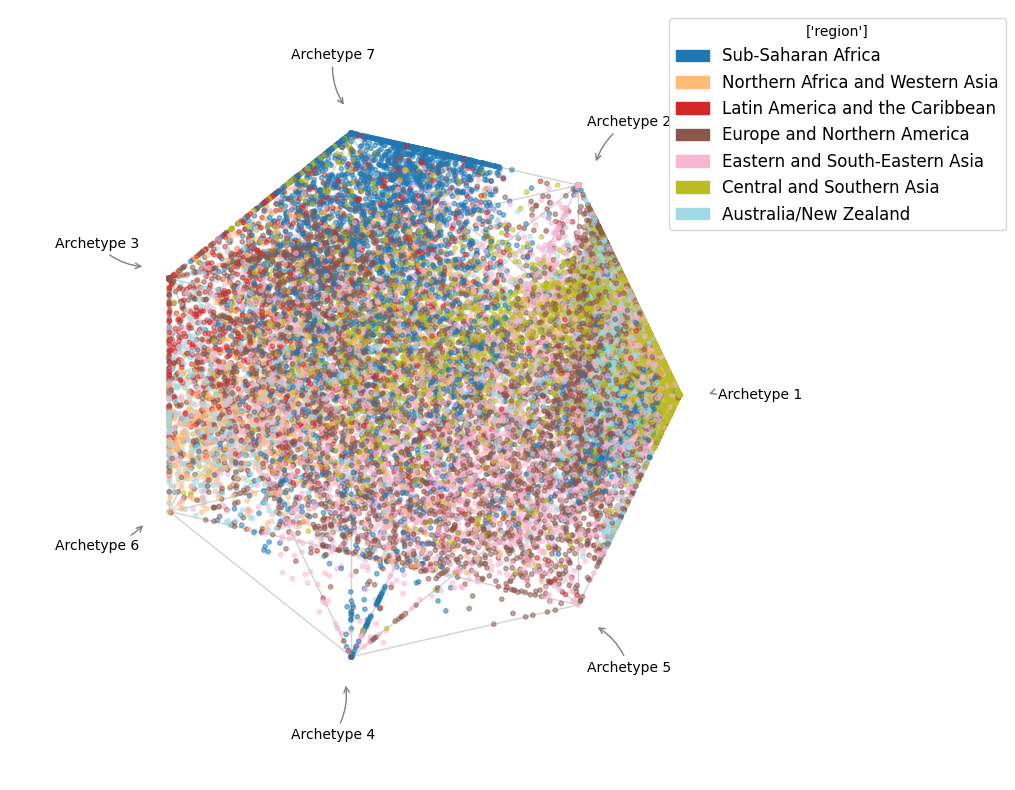

In [10]:
# FOR COUNTRY
filter_cols = ["region"]

metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

# Only samples that are in "Europe and North America"
# metadata = metadata[metadata["region"].isin(["Europe and Northern America"])]

plot_simplex(otu_aa_swapped, metadata, filter_cols, cmap_name="tab20", legend_type="discrete", remove_nan=True, alpha = 0.5, s=10, remove_values={"region": "unknown"}, figsize=(12, 10))

Similarly, for age. This time, the `legend_type` is "continuous"

C:\Users\rayve\AppData\Local\Temp\ipykernel_39204\1000916921.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[present_idx, col])


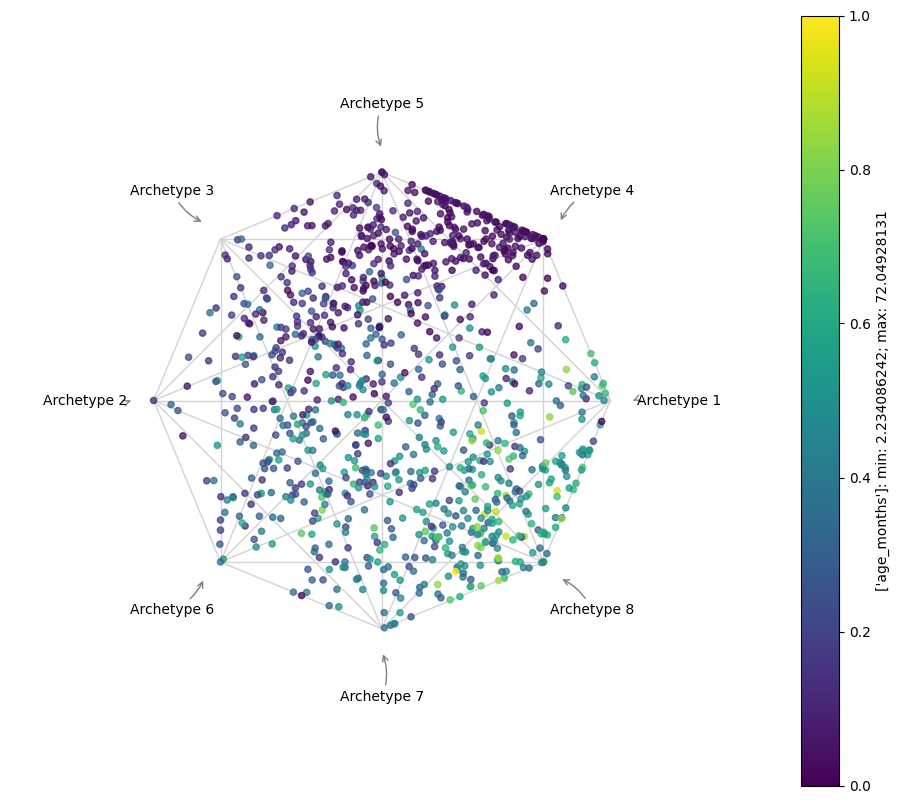

In [155]:
# FOR AGE
filter_cols = ["age_months"]

metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

plot_simplex(otu_aa_swapped, metadata, ["age_months"], "viridis", "continuous", remove_nan=True, alpha=0.75, s=20, figsize=(12, 10))

### Group Plotting

C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1532552647.py:27: DtypeWarning: Columns (3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_table(r"datasets\tsv\hadza_meta_formatted.tsv", index_col=0)
  0%|          | 0/6 [00:00<?, ?it/s]C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1000916921.py:54: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels =

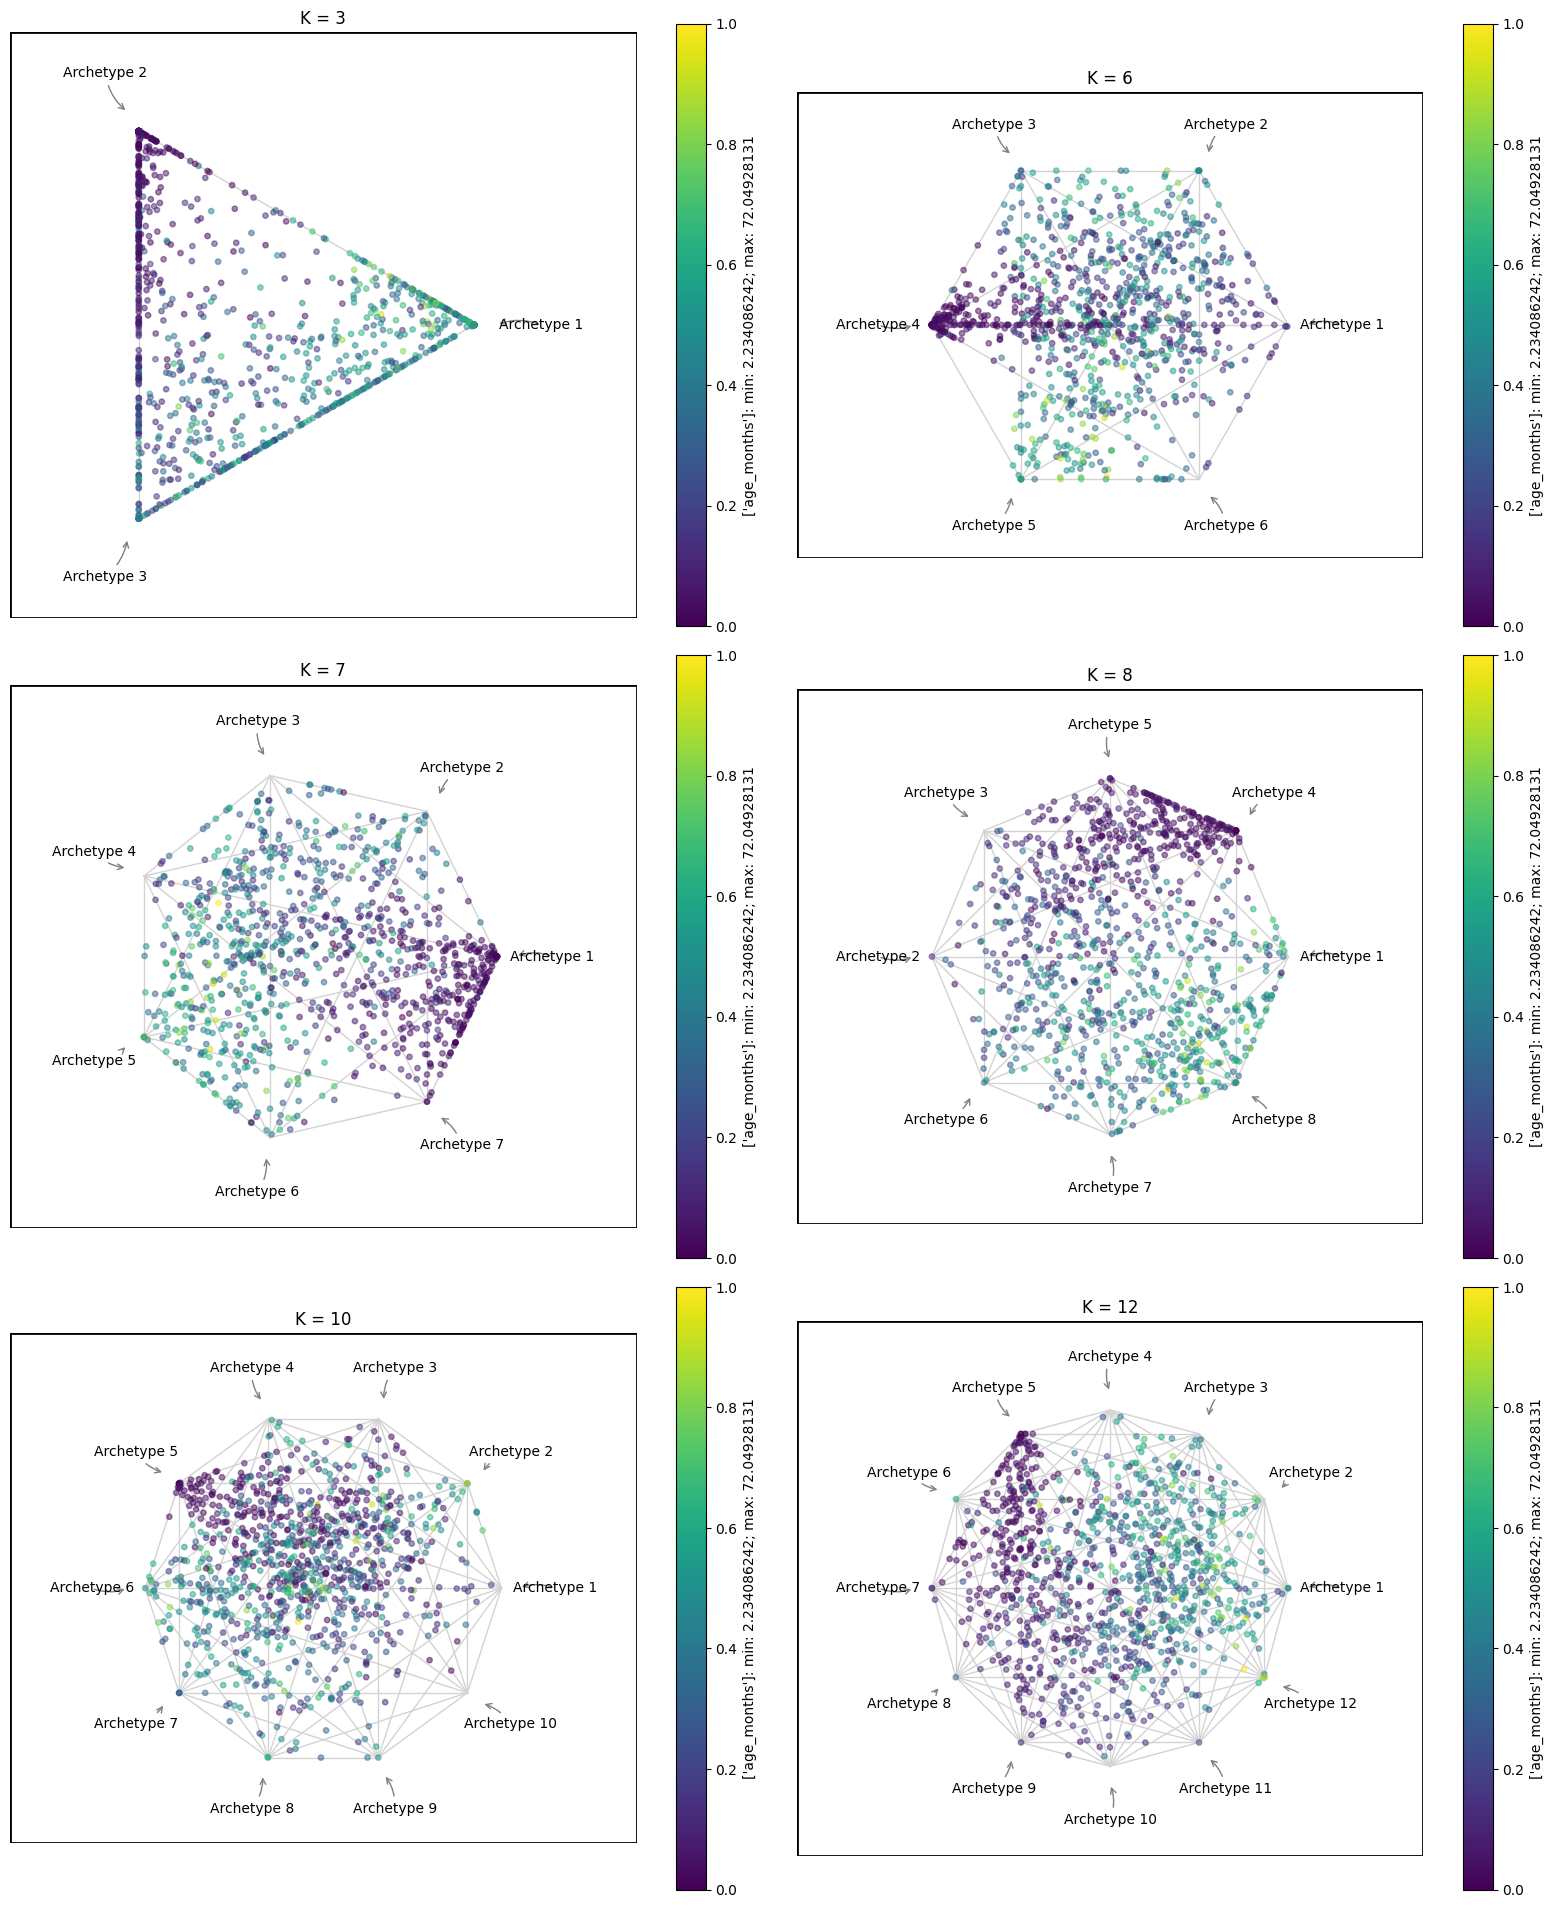

In [11]:
dir = r"results\Hadza\norm_qc_age1k"
filter_cols = ["age_months"]
legend_type = "continuous" # "discrete" 

remove_values = {} #{"sample_type": "unknown"}

numKs =  [3,6,7,8,10,12] #[3,6,7,8,9,11] # 
swapped_cols = {
    # Region7k 
    # 8: ["Archetype 1", "Archetype 4", "Archetype 8", "Archetype 7", "Archetype 6", "Archetype 2", "Archetype 5", "Archetype 3"],
    # Region30k
    # 7: [ "Archetype 1","Archetype 2", "Archetype 7", "Archetype 3","Archetype 6", "Archetype 4", "Archetype 5"]
    # Region3k_AdultsOnly
    # 10: ["Archetype 1", "Archetype 2", "Archetype 3", "Archetype 9", "Archetype 4", "Archetype 8", "Archetype 5", "Archetype 6", "Archetype 7",  "Archetype 10"],
    # Hadza Region10k
    # 7: ["Archetype 1", "Archetype 3", "Archetype 6", "Archetype 2",  "Archetype 4", "Archetype 7", "Archetype 5"],
    # Hadza Age1k
    8: ["Archetype 1", "Archetype 4", "Archetype 5","Archetype 3", "Archetype 2",  "Archetype 6", "Archetype 7", "Archetype 8"],
}


# projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
# meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
# tags = pd.read_table("datasets/compendium/tags.tsv")

projects = pd.DataFrame()
meta = pd.read_table(r"datasets\tsv\hadza_meta_formatted.tsv", index_col=0)
tags = pd.DataFrame()

# Make subplot for each K
numPlots = len(numKs)
numCols = 2
numRows = int(np.ceil(numPlots / numCols))

plotSize = (8,8)
figSize = (plotSize[0]*numCols, (plotSize[1]*0.8)*numRows)

if legend_type == "discrete":
    cmap_name = "tab10"
else:
    cmap_name = "viridis"

# Make fig ax with borders
fig, ax = plt.subplots(numRows, numCols, figsize=figSize, tight_layout=True)

for i, k in tqdm(enumerate(numKs), total=numPlots): 
    f = f"otu_AA_K{k}_1.0_None_jensenshannon.json"
    fName = os.path.join(dir, f)
    otu_dict = json.load(open(fName, "r"))

    otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
    if k in swapped_cols:
        otu_aa = otu_aa[swapped_cols[k]]

    aa_labels = np.array(otu_dict["labels"])
    aa_archetypes = otu_dict["archetypes"]
    info = {
        "perms": otu_dict["info_perms"],
    }
    n_archs = len(aa_archetypes)

    metadata = extract_metadata_compendium(otu_aa.index, tags, meta, projects, filter_cols)

    axis = ax[i // numCols, i % numCols] if numPlots > 1 else ax
    plot_simplex(otu_aa, metadata, filter_cols, cmap_name=cmap_name, legend_type=legend_type, remove_nan=True, alpha = 0.5, s=15, remove_values=remove_values, figsize=plotSize, ax = axis, legend_fontsize=10)
    
    axis.set_title(f"K = {k}")
    xlim, ylim = axis.get_xlim(), axis.get_ylim()
    rect = plt.Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0], linewidth=2, edgecolor='black', facecolor='none')
    axis.add_patch(rect)


fig.tight_layout()

## Display Archetype Composition

In [13]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region30k\otu_AA_K7_1.0_None_jensenshannon.json"
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)


In [14]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = r"datasets\compendium\normalized\compendium_Norm_QC-region30k.csv"

try: 
    otu = pd.read_csv(otuFile, index_col="sample")
except: 
    otu = pd.read_csv(otuFile, index_col=0) 
# otu.drop("Unnamed: 0", axis=1, inplace=True)


### Separate Bar Charts

C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1969942952.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[x,y].set_xticklabels(ax[x,y].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1969942952.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[x,y].set_xticklabels(ax[x,y].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1969942952.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[x,y].set_xticklabels(ax[x,y].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_40732\1969942952.py:78: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or usin

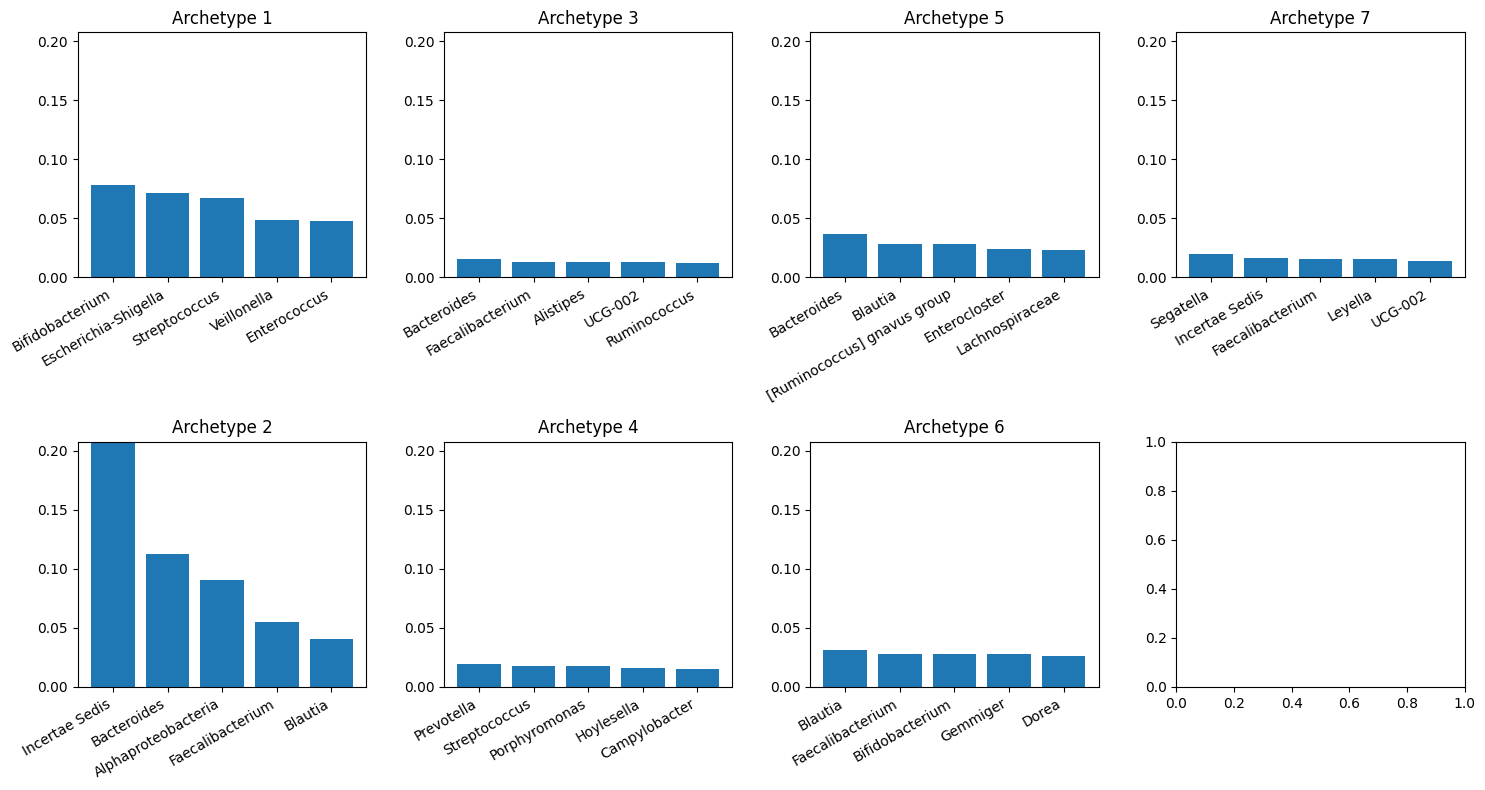

In [16]:
# archs = pd.DataFrame(aa_archetypes, columns=grouped_cols, index=[f"Archetype {i+1}" for i in range(n_archs)])
n_archs = len(aa_archetypes)
archs = pd.DataFrame(aa_archetypes, columns=otu.columns, index=[f"Archetype {i+1}" for i in range(n_archs)])

NUM_TAXA = 5

# Extract the top 5 taxa for each archetype

# For each row in archs, sort the values in descending order

tax_sorted_archs = archs.copy()
for i in range(archs.shape[0]):
    tax_sorted_archs.iloc[i] = tax_sorted_archs.iloc[i].sort_values(ascending=False)

# sorted_archs = archs.apply(lambda x: x.sort_values(ascending=False), axis=0)
top_n_taxa_archs = tax_sorted_archs.iloc[:, :NUM_TAXA]

# Go through each top taxa archetype, and find the column from which the value comes from

top_taxa_archs = [] # 2D Tuples (value, taxa)
for i,arch in top_n_taxa_archs.iterrows():
    top_taxa  = []
    for val in arch:
        # Find the column from which the value comes from in Row i from archs dataframe
        taxa = archs.loc[i][archs.loc[i] == val].index[0]
        top_taxa.append((val, taxa))

    top_taxa_archs.append(top_taxa)


# Find the percentage of each taxon in the archetype w.r.t archs
for i, arch in enumerate(top_taxa_archs):
    total = archs.loc[f"Archetype {i+1}"].sum()
    for j, (val, taxa) in enumerate(arch):
        top_taxa_archs[i][j] = (val/total, taxa)

# For each arch, add a new element ("Others") with the value 1 - sum of all other values
for i, arch in enumerate(top_taxa_archs):
    top_taxa_archs[i].append((1 - sum([val for val, taxa in arch]), "Others"))

# Make similar graphs but for bar plot, make sure to color the bars, and label them with respective index as above
# Set the same y-axis for all bar plots, which is the maximum value of all archetypes in top_taxa_archs

max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

vertical=False

if vertical: 
    fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(8, 15))
else: 
    fig, ax = plt.subplots(2, (n_archs+1) // 2, figsize=(15, 8))
for i, arch in enumerate(top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa for val, taxa in arch]

    # print(f"**Archetype {i+1}**")
    # print()
    # for k, label in enumerate(labels):
    #     print(f"***Label {k+1}***: {label} \n")
    # print("\n")

    plotLabels = []
    for k, label in enumerate(labels[:-1]):
        curr = label.split(".")[0]
        for t in label.split("."):
            if(t == "NA"):
                break
            curr = t
        plotLabels.append(curr)
    
    plotLabels += ["Others"]

    x,y = (i//2, i % 2) if vertical else (i % 2, i // 2)

    ax[x,y].bar(plotLabels[:-1], vals[:-1])
    ax[x,y].set_title(f"Archetype {i+1}")
    ax[x,y].set_ylim(0, max_val)
    ax[x,y].set_xticklabels(ax[x,y].get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()



### Stacked Bar Chart

Total unique top taxa across all archetypes: 25


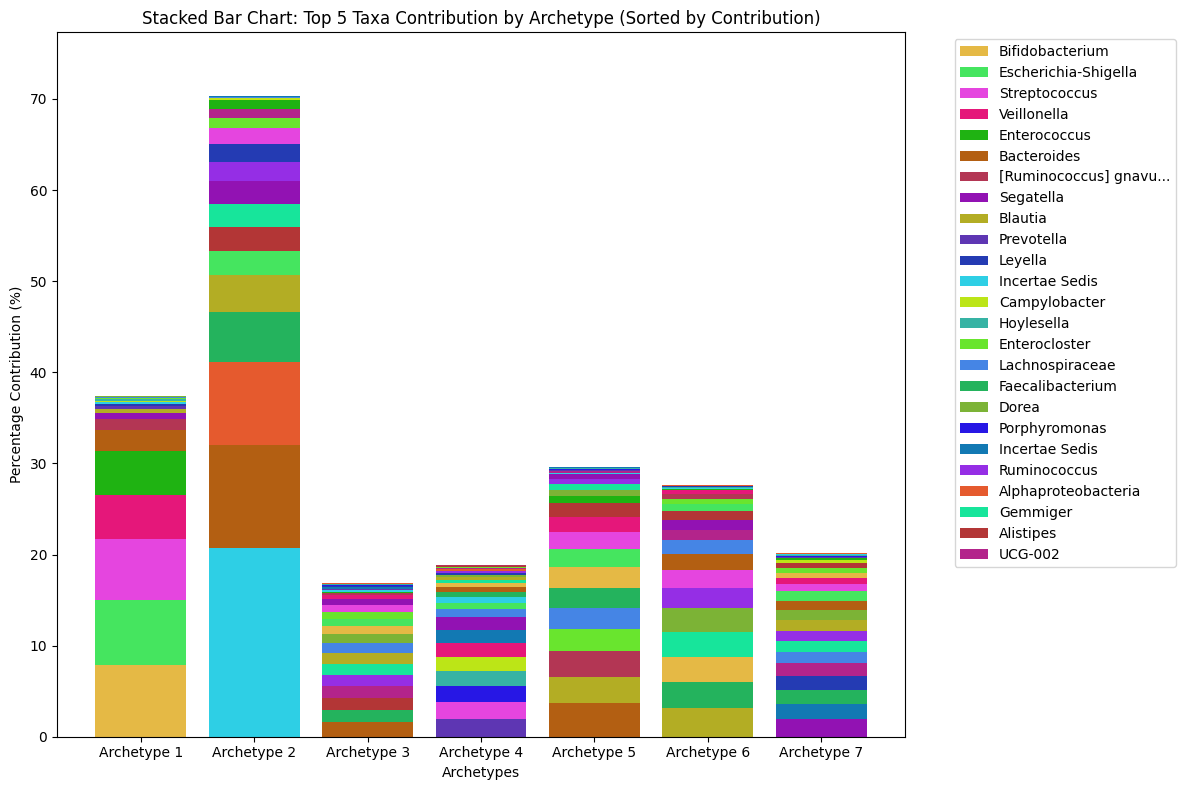


Summary:
Number of archetypes: 7
Number of top taxa per archetype: 5
Total unique taxa across all archetypes: 25

Detailed breakdown:

Archetype 1:
  Bifidobacterium: 7.86%
  Escherichia-Shigella: 7.13%
  Streptococcus: 6.72%
  Veillonella: 4.86%
  Enterococcus: 4.77%
  Bacteroides: 2.32%
  [Ruminococcus] gnavu...: 1.23%
  Segatella: 0.67%
  Blautia: 0.46%
  Prevotella: 0.26%
  Leyella: 0.23%
  Incertae Sedis: 0.22%
  Campylobacter: 0.17%
  Hoylesella: 0.14%
  Enterocloster: 0.14%

Archetype 2:
  Incertae Sedis: 20.76%
  Bacteroides: 11.30%
  Alphaproteobacteria: 9.07%
  Faecalibacterium: 5.48%
  Blautia: 4.09%
  Escherichia-Shigella: 2.63%
  Alistipes: 2.61%
  Gemmiger: 2.58%
  Segatella: 2.42%
  Ruminococcus: 2.17%
  Leyella: 1.99%
  Streptococcus: 1.72%
  Enterocloster: 1.05%
  UCG-002: 1.04%
  Enterococcus: 1.00%
  Campylobacter: 0.17%
  Lachnospiraceae: 0.16%

Archetype 3:
  Bacteroides: 1.57%
  Faecalibacterium: 1.34%
  Alistipes: 1.33%
  UCG-002: 1.29%
  Ruminococcus: 1.24%
  G

In [18]:
# Get the union of all top contributing taxa across all archetypes
all_top_taxa = set()
for arch in top_taxa_archs:
    for val, taxa in arch[:-1]:  # Exclude "Others"
        all_top_taxa.add(taxa)

all_top_taxa = list(all_top_taxa)

# Function to simplify taxa names for better readability
def simplify_taxa_name(taxa_name):
    """Extract the most informative part of the taxonomic name"""
    if taxa_name == "Others":
        return "Others"
    
    # Split by dots and get the last meaningful part
    parts = taxa_name.split('.')
    
    parts = [part for part in parts if part and part not in ["NA", "unknown", "unclassified", "."]]
    taxa_name = parts[-1] if parts else taxa_name
    
    return taxa_name[:20] + "..." if len(taxa_name) > 20 else taxa_name

# Create simplified mapping and sort by display names
simplified_mapping = {taxa: simplify_taxa_name(taxa) for taxa in all_top_taxa}
all_top_taxa = sorted(all_top_taxa, key=lambda x: simplified_mapping[x])

print(f"Total unique top taxa across all archetypes: {len(all_top_taxa)}")

# Create data structure for stacked bar chart
archetype_names = [f"Archetype {i+1}" for i in range(n_archs)]
taxa_percentages = {}

# Initialize all taxa percentages to 0 for each archetype
for taxa in all_top_taxa:
    taxa_percentages[taxa] = [0] * n_archs

# Fill in the actual percentages for ALL taxa in all_top_taxa (not just top N per archetype)
for arch_idx in range(n_archs):
    arch_name = f"Archetype {arch_idx+1}"
    total = archs.loc[arch_name].sum()
    
    for taxa in all_top_taxa:
        if taxa in archs.columns:
            # Get the actual percentage of this taxa in this archetype
            taxa_percentages[taxa][arch_idx] = (archs.loc[arch_name, taxa] / total) * 100
        else:
            taxa_percentages[taxa][arch_idx] = 0

# Create simplified stacked bar chart
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 8))

# Set up the bar positions
x_pos = np.arange(len(archetype_names))
bottom = np.zeros(len(archetype_names))

# Define colors for each taxa - use a better colormap strategy for many taxa
def generate_distinct_colors(n_colors):
    """Generate n distinct colors using a combination of colormaps and HSV space"""
    if n_colors <= 12:
        # For small numbers, use qualitative colormap
        return plt.cm.Set3(np.linspace(0, 1, n_colors))
    elif n_colors <= 20:
        # For medium numbers, use tab20
        return plt.cm.tab20(np.linspace(0, 1, n_colors))
    else:
        # For large numbers, generate colors in HSV space for maximum distinction
        import colorsys
        colors = []
        for i in range(n_colors):
            hue = i / n_colors
            saturation = 0.7 + (i % 3) * 0.1  # Vary saturation slightly
            value = 0.7 + (i % 2) * 0.2       # Vary brightness slightly
            rgb = colorsys.hsv_to_rgb(hue, saturation, value)
            colors.append(rgb)
        return colors

colors = generate_distinct_colors(len(all_top_taxa))

# Create stacked bars with taxa sorted by contribution for each archetype
# Keep track of which taxa we've already added to legend
legend_added = set()

# For each archetype, we need to sort taxa by their contribution (highest at bottom)
for arch_idx in range(len(archetype_names)):
    # Get taxa and their contributions for this archetype, sorted by contribution (descending)
    arch_taxa_contrib = []
    for taxa in all_top_taxa:
        contrib = taxa_percentages[taxa][arch_idx]
        if contrib > 0:  # Only include taxa with non-zero contributions
            arch_taxa_contrib.append((taxa, contrib))
    
    # Sort by contribution (highest first, will be at bottom of stack)
    arch_taxa_contrib.sort(key=lambda x: x[1], reverse=True)
    
    # Create the stacked segments for this archetype
    bottom_val = 0
    for taxa, contrib in arch_taxa_contrib:
        taxa_idx = all_top_taxa.index(taxa)  # Get original index for color consistency
        simplified_name = simplified_mapping[taxa]  # Use pre-computed simplified name
        
        # Add to legend only if we haven't seen this taxa before
        label = simplified_name if taxa not in legend_added else ""
        if taxa not in legend_added:
            legend_added.add(taxa)
        
        # Plot this segment
        ax.bar(arch_idx, contrib, bottom=bottom_val, color=colors[taxa_idx], label=label)
        bottom_val += contrib

# Customize the plot
ax.set_xlabel('Archetypes')
ax.set_ylabel('Percentage Contribution (%)')
ax.set_title(f'Stacked Bar Chart: Top {NUM_TAXA} Taxa Contribution by Archetype (Sorted by Contribution)')
ax.set_xticks(x_pos)
ax.set_xticklabels(archetype_names)
# Calculate max height for y-axis limit
max_height = max([sum([taxa_percentages[taxa][arch_idx] for taxa in all_top_taxa 
                      if taxa_percentages[taxa][arch_idx] > 0]) 
                  for arch_idx in range(len(archetype_names))])
ax.set_ylim(0, max_height * 1.1 if max_height > 0 else 100)

# Add legend
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

# Print summary information
print(f"\nSummary:")
print(f"Number of archetypes: {n_archs}")
print(f"Number of top taxa per archetype: {NUM_TAXA}")
print(f"Total unique taxa across all archetypes: {len(all_top_taxa)}")

# Print detailed breakdown for each archetype
print(f"\nDetailed breakdown:")
for arch_idx, arch_name in enumerate(archetype_names):
    print(f"\n{arch_name}:")
    # Get non-zero taxa for this archetype (excluding "Others")
    arch_taxa = []
    for taxa in all_top_taxa:
        if taxa_percentages[taxa][arch_idx] > 0:
            simplified = simplified_mapping[taxa]  # Use pre-computed simplified name
            arch_taxa.append((simplified, taxa_percentages[taxa][arch_idx], taxa))
    
    # Sort by percentage (descending)
    arch_taxa.sort(key=lambda x: x[1], reverse=True)
    
    for simplified, percentage, original in arch_taxa:
        if percentage > 0.1:  # Only show taxa with >0.1% contribution
            print(f"  {simplified}: {percentage:.2f}%")

### Automated Blast

In [ ]:
import xml.etree.ElementTree as ET

def parseBlastXml(source): 

    taxa_hits = {}

    # tree = ET.parse(ET.fromstring(source))
    root = ET.fromstring(source)

    # Find all the hits, store them in a list of dictionaries, include sub children as well
    hits = []
    for iteration in root.findall(".//Iteration"):
        taxa_hits[iteration.find("Iteration_query-def").text] = []

        for hit in iteration.findall(".//Iteration_hits/Hit"):
            hit_dict = {}
            for child in hit:
                try: 
                    hit_dict[child.tag] = float(child.text) 
                except:
                    hit_dict[child.tag] = child.text
                if(child.tag == "Hit_hsps"):
                    hit_dict["Hsps"] = {}
                    hsps = child.findall(".//Hsp")[0].findall("./")
                    for hsp in hsps:
                        try: 
                            hit_dict["Hsps"][hsp.tag] = float(hsp.text)
                        except ValueError as e:
                            hit_dict["Hsps"][hsp.tag] = hsp.text

            taxa_hits[iteration.find("Iteration_query-def").text].append(hit_dict)


    return taxa_hits

# with open("my_blast.xml", "r") as f:
#     hits = parseBlastXml(f.read())
#     print(hits)


In [ ]:
# write all the taxa in FASTA format file

def writeFasta(taxa, outPath):
    # Create the file if not exists
    with open(outPath, "a") as out_stream:
        out_stream.write(f">{taxa}\n")
        out_stream.write(f"{taxa}\n")

for arch in top_taxa_archs:
    for val, taxa in arch:
        if taxa == "Others":
            continue
        writeFasta(taxa, f"temp.fasta")


In [ ]:
from Bio import Blast

with open ("temp.fasta", "r") as in_stream:
    src = in_stream.read()

result_stream = Blast.qblast("blastn", "ref_prok_rep_genomes", src)

with open("my_blast.xml", "wb") as out_stream:
    out_stream.write(result_stream.read())

result_stream.close()

In [ ]:
with open("my_blast.xml", "r") as f:
    taxa_hits = parseBlastXml(f.read())

NUM_HITS = 3
filtered_hits = {}

for taxa, hits in taxa_hits.items():
    sorted_hits = sorted(hits, key=lambda x: x["Hsps"]["Hsp_evalue"])
    filtered_hits[taxa] = sorted_hits[:NUM_HITS]



C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used 

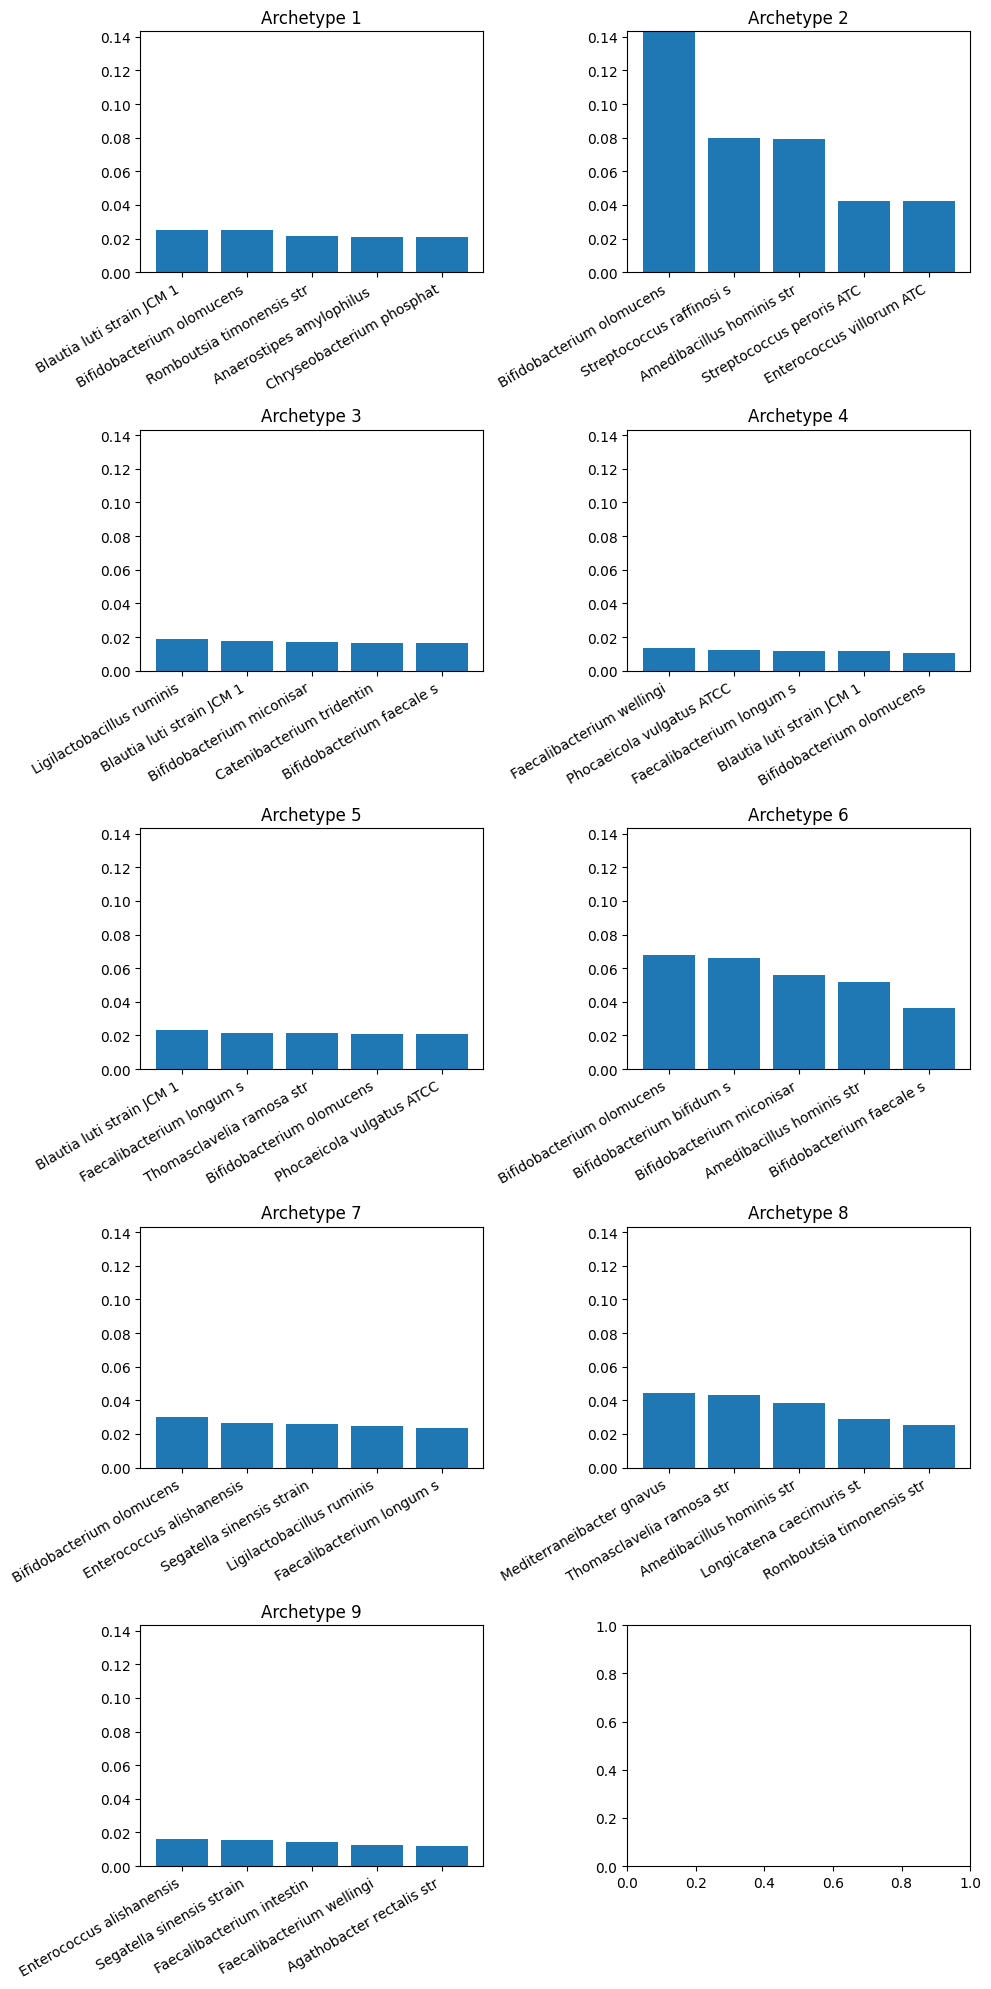

In [ ]:
max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))

labelled_top_taxa_archs = []


# Take top taxa archs and copy it into labelled_top_taxa_archs using loops
for i, arch in enumerate(top_taxa_archs):
    labelled_top_taxa_archs.append([])
    for val, taxa in arch:
        if taxa == "Others":
            labelled_top_taxa_archs[i].append([val, taxa])
            continue
        labelled_top_taxa_archs[i].append((val, filtered_hits[taxa]))


MAX_LABEL_LEN = 25

# I wanna kill myself this is so shit ohmygod TODO FIX
for i, arch in enumerate(labelled_top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa[0]["Hit_def"][:MAX_LABEL_LEN] for val, taxa in arch[:-1]]
    labels.append("Others")
    # print(labels[0]["Hit_def"])
    # print(f"**Archetype {i+1}**")
    # print()
    # for k, label in enumerate(labels):
    #     print(f"***Label {k+1}***: {label} \n")
    # print("\n")
    plotLabels = [f"{i+0}" for i in range(len(labels)-1)] + ["Others"]
    ax[i // 2, i % 2].bar(labels[:-1], vals[:-1])
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")
    ax[i // 2, i % 2].set_ylim(0, max_val)
    ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()



### Loss Analysis

(6804, 3)
(6804, 4)
(6804, 5)
(6804, 6)
(6804, 7)
(6804, 8)
(6804, 9)
(6804, 10)
(6804, 11)
(6804, 12)
(6804, 14)
(6804, 15)
Arch 3: 9041982.35808466
Arch 4: 8364947.517900469
Arch 5: 8038953.363329947
Arch 6: 7760861.96238741
Arch 7: 7586226.945857908
Arch 8: 24848519.011912197
Arch 9: 21727791.36283116
Arch 10: 7179510.964153438
Arch 11: 7908469.64364399
Arch 12: 6992430.739905717
Arch 14: 21024155.236029185
Arch 15: 6825115.617798014


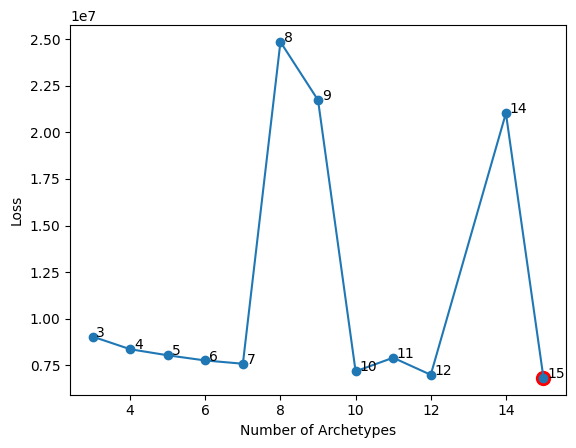

In [ ]:
# Read all json files from /results/SBATCH_N3_N12, and plot the loss vs n_archetypes
import glob
import json

jsonFiles = glob.glob(r"results\Compendium_N3_N13_NoPC_NoGlom\Norm-Region\*.json")

losses = []

nIdx_archs = [3,4,5,6,7,8,9,10,11,12,14,15]


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in nIdx_archs:
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
            print(otu_aa.shape)
            arch_losses[n] = otu_dict["loss"][-1]    


plt.plot(arch_losses.keys(), arch_losses.values(), marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Loss")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(nIdx_archs):
    print(f"Arch {txt}: {arch_losses[txt]}")
    plt.annotate(f"{txt}", (nIdx_archs[i] + pad, arch_losses[txt] + pad))

# Plot the smallest loss in green
min_loss = min(arch_losses.values())
min_key = [key for key, value in arch_losses.items() if value == min_loss][0]
plt.scatter(min_key, min_loss, color="red", s=100)

plt.show()



### PCoA Comparison

In [56]:
otuFile = r"datasets\compendium\normalized\compendium_Norm_QC-region30k.csv"

# For Compendium Dataset
otu = pd.read_csv(otuFile, index_col="sample")
projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")

# For Hadza Dataset
# otu = pd.read_csv(otuFile, index_col=0)
# projects = pd.DataFrame()
# meta = pd.read_table(r"datasets\tsv\hadza_meta_formatted.tsv", index_col=0)
# tags = pd.DataFrame()

In [57]:
pcoa_data = otu.copy()
print(f"Before shape: {pcoa_data.shape}")
pcoa_data = pcoa_data.map(lambda x: np.log2(x+1))
pcoa_data = pcoa_data.replace([np.inf, -np.inf], np.nan)
pcoa_data = pcoa_data.dropna()
pcoa_data = pcoa_data[(pcoa_data > 0).sum(axis=1) > 0]
print(f"After shape: {pcoa_data.shape}")

Before shape: (29117, 991)
After shape: (27751, 991)


In [58]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

method = scipy.spatial.distance.jensenshannon  #'jensenshannon' # or "jensenshannon", unifrac is problematic
bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA


KeyboardInterrupt: 

In [ ]:
print(np.isnan(bdiv.data).sum(), np.isinf(bdiv.data).sum())

0 0


In [ ]:
pcoa_results = pcoa(bdiv, number_of_dimensions=5)

# Extract the coordinates
pcoa_coordinates = pcoa_results.samples

C:\Users\rayve\AppData\Local\Temp\ipykernel_36088\4224174029.py:58: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  axs[i].set_xlabel(f"{x_pc} ({pcoa_results.proportion_explained[int(x_pc[-1])-1]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_36088\4224174029.py:59: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  axs[i].set_ylabel(f"{y_pc} ({pcoa_results.proportion_explained[int(y_pc[-1])-1]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_36088\4224174029.py:67: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. 

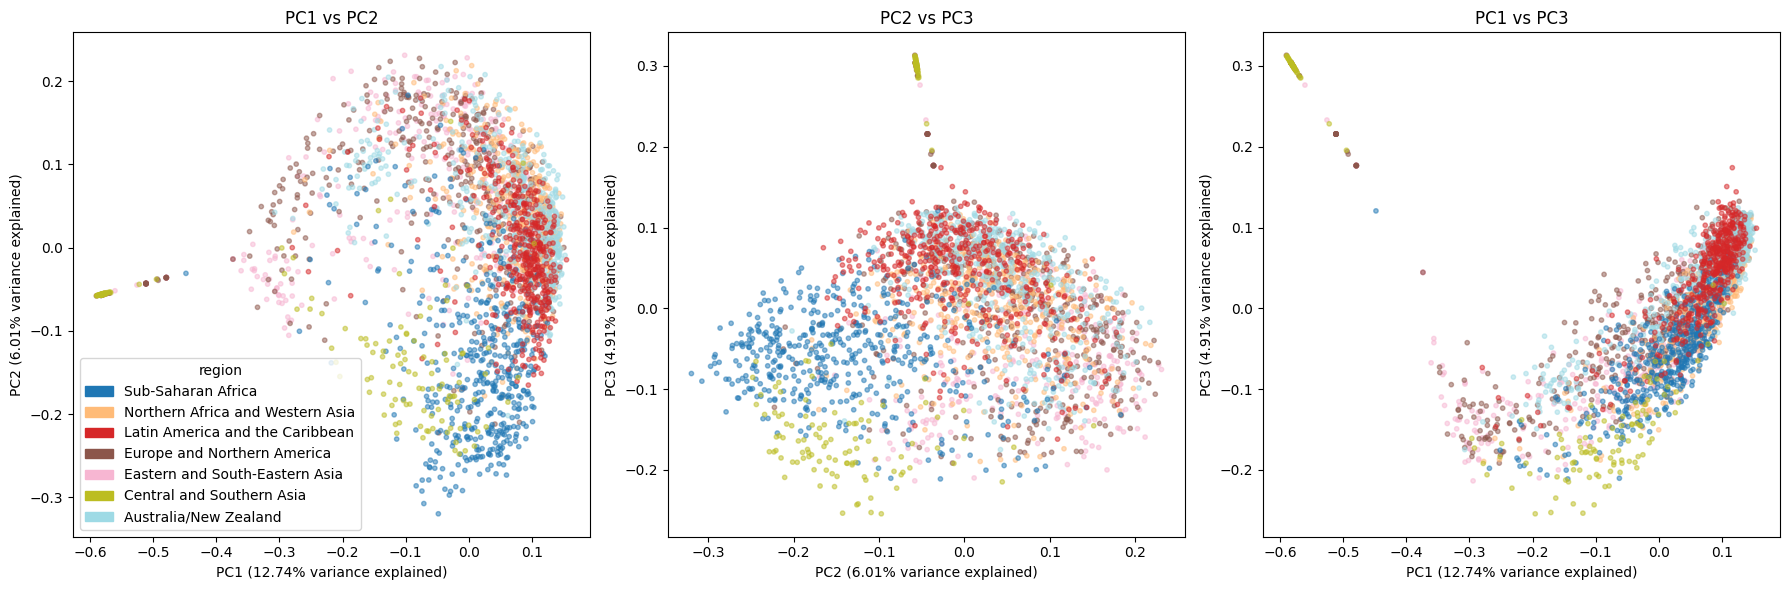

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.cm as cm

def add_discrete_legend(ax, unique_colors, cmap):
    legend_patches = [
        Patch(color=cmap(unique_colors[c]), label=c)
        for c in unique_colors
    ]
    # Add the legend to the plot
    ax.legend(handles=legend_patches, title=filter_col, loc='lower left')

def add_continuous_legend(ax, filter_labels, cmap):
    # Add the legend to the plot with appropriate min and max values
    cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
    cbar.set_label(f"{filter_col}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )



filter_col = "region"
legend_type = "discrete" # "discrete" or "continuous"

# Create color list for according to filter_col
metadata = extract_metadata_compendium(pcoa_coordinates.index, tags, meta, projects, [filter_col])
filter_labels = pd.Series(index=pcoa_coordinates.index, dtype=str)

for col in [filter_col]:
    filter_labels = filter_labels.fillna(metadata.loc[pcoa_coordinates.index, col])

if(legend_type == "discrete"):
    unique_colors = {c: i for i, c in enumerate(sorted(filter_labels.unique(), reverse=True) )}
    color = filter_labels.map(unique_colors)
    cmap = "tab20"
elif(legend_type == "continuous"):
    unique_colors = filter_labels
    color = filter_labels.astype(float)
    cmap = "viridis"


# Create a scatter plot
fig, axs = plt.subplots(1, 3, figsize=(18, 6))  # 1 row, 3 columns

pcs = [
    ('PC1', 'PC2'),
    ('PC2', 'PC3'),
    ('PC1', 'PC3')
]

for i, (x_pc, y_pc) in enumerate(pcs):
    axs[i].scatter(
        pcoa_coordinates[x_pc],
        pcoa_coordinates[y_pc],
        s=10,
        c=color,
        cmap=cmap,
        alpha=0.5
    )
    axs[i].set_xlabel(f"{x_pc} ({pcoa_results.proportion_explained[int(x_pc[-1])-1]:.2%} variance explained)")
    axs[i].set_ylabel(f"{y_pc} ({pcoa_results.proportion_explained[int(y_pc[-1])-1]:.2%} variance explained)")
    axs[i].set_title(f"{x_pc} vs {y_pc}")

    # Add legend or colorbar only to the first plot for clarity
    if i == 0:
        if legend_type == "continuous":
            plt.colorbar(cm.ScalarMappable(cmap="viridis"), ax=axs[i], label=filter_col)
        else:
            add_discrete_legend(axs[i], unique_colors, plt.cm.get_cmap("tab20", len(unique_colors)))

plt.tight_layout()
plt.show()
# # Add sample labels if desired
# for idx, row in pcoa_coordinates.iterrows():
#     plt.annotate(idx, (row['PC1'], row['PC2']))




## Num Archs Analysis

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def calc_scores(otu, labels, discretize=False, buckets=None):
    """
    Calculate the silhouette score, Davies-Bouldin score, and Calinski-Harabasz score for the given data.
    otu: numpy array of shape (N, M)
    labels: numpy array of shape (N,)
    """
    if discretize:
        assert buckets is not None, "If discretizing, tuple buckets must be provided."
        # Discretize the data into buckets
        new_labels = labels.tolist()
        for i in range(len(labels)):
            for bucket in buckets: 
                if labels[i] >= bucket[0] and labels[i] < bucket[1]:
                    new_labels[i] = f"{bucket[0]}-{bucket[1]}"
                    break
        labels = np.array(new_labels)

    silhouette = silhouette_score(otu, labels)
    db_score = davies_bouldin_score(otu, labels)
    # ch_score = calinski_harabasz_score(otu, labels)

    return {
        "silhouette": silhouette,
        "davies_bouldin": db_score,
    }

100%|██████████| 10/10 [01:47<00:00, 10.76s/it]


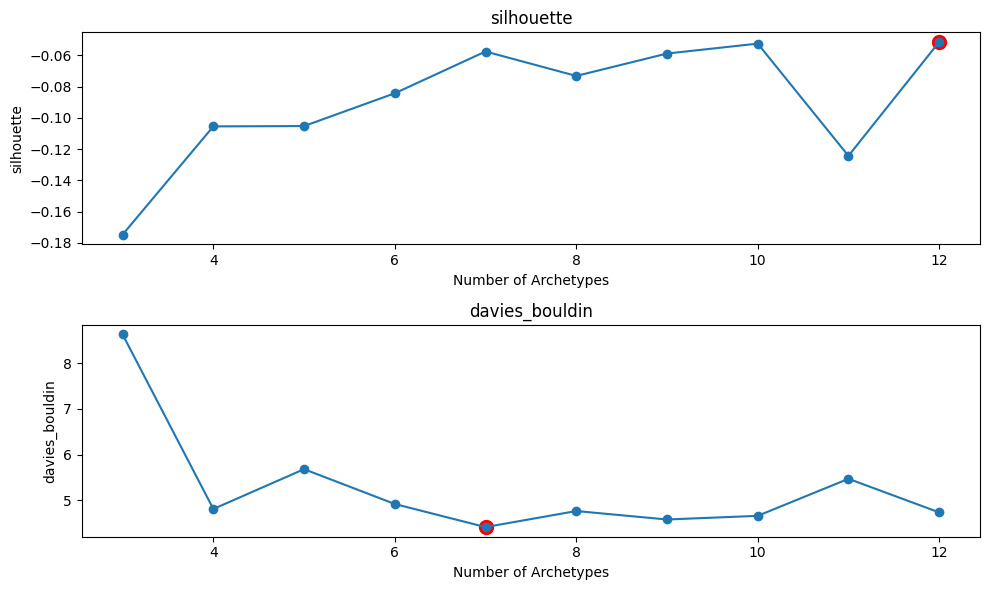

In [ ]:
buckets = [(0,3), (3,6), (6,12), (12,24), (24,36), (36,48), (48,60), (60, np.inf)]

import glob
from tqdm import tqdm

jsonFiles = glob.glob(r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region30k/*.json")
filter_cols = ["region"]
discretize = False

losses = []

nIdx_archs = [3,4,5,6,7,8,9,10,11,12] #[5,6,7,8,9,10] #

projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")

# projects = pd.DataFrame()
# meta = pd.read_table(r"datasets\tsv\hadza_meta_formatted.tsv", index_col=0)
# tags = pd.DataFrame()

# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in tqdm(nIdx_archs):
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])

            metadata = extract_metadata_compendium(otu_aa.index, tags, meta, projects, filter_cols)
            labels = metadata[filter_cols[0]].to_numpy()
            scores = calc_scores(otu_aa, labels, discretize=discretize, buckets=buckets)

            arch_losses[n] = scores
            # print(f"Scores for K={n}:", scores)


# Create a plot with 3 lines for each score in a different sub plots
numScores = len(arch_losses[nIdx_archs[0]].keys())
fig, axs = plt.subplots(numScores, 1, figsize=(10, 3*numScores))

for i, score in enumerate(arch_losses[nIdx_archs[0]].keys()):
    axs[i].plot(arch_losses.keys(), [arch_losses[n][score] for n in arch_losses.keys()], marker="o")
    axs[i].set_xlabel("Number of Archetypes")
    axs[i].set_ylabel(score)
    axs[i].set_title(score)

    # Highlight the best score in red
    best_func = max
    if(score == "davies_bouldin"): 
        best_func = min

    best_score = best_func([arch_losses[n][score] for n in arch_losses.keys()])
    best_key = [key for key, value in arch_losses.items() if value[score] == best_score][0]
    axs[i].scatter(best_key, best_score, color="red", s=100)

plt.tight_layout()


## Compendium Dataset Format Manipulation

### Data Normalization

### Normalizing Function

In [ ]:
def normalize_data(control, normalize, otu, meta, tags, projects, continuous=False, saveDir =None, saveName=None, ignore_zero=True, ignore = [], tol=0, verbose=False): 
    """
    Normalize the data based on control and normalize parameters.
    Parameters:
    control: dict
        Dictionary with keys as column names and values as the values to filter by.
    normalize: dict
        Dictionary with keys as column names and values as the values to normalize by.
    otu: DataFrame
        The OTU table to normalize.
    meta: DataFrame
        The metadata for the samples.
    tags: DataFrame
        The tags for the samples.
    projects: DataFrame
        The projects for the samples.
    saveDir: str (optional)
        The directory to save the normalized data to. If None, the data will not be saved.
    ignore_zero: bool (optional)
        Whether to ignore samples with zero counts in the normalization process.
    ignore: list (optional)
        List of values to ignore in the normalization process.
    tol: float (optional)
        Tolerance for the number of samples to normalize to (% of minimum label). If tol is 0, all samples will be used.
    verbose: bool (optional)
        Whether to print verbose output during the normalization process.
    Returns:
        normalized_otu: DataFrame
            The normalized OTU table.
        normalized_meta: DataFrame
            The filtered metadata with the normalized samples.
    """
    columns_of_interest = list(control.keys()) + list(normalize.keys())
    filtered_df = extract_metadata_compendium(meta.index, tags, meta, projects, columns_of_interest)
    if verbose:
        print(f"Number of samples before control Normalization: {len(filtered_df)}")
    
    for label, values in control.items():
        if values is None:
            values = filtered_df[label].unique()
            values = values[~pd.isnull(values)]
            
        filtered_df = filtered_df[filtered_df[label].isin(values)]
    if verbose:
        print(f"Number of samples after control filtering: {len(filtered_df)}")

    ignored = 0
    normalized_meta = pd.DataFrame()
    min_counts = np.inf
    min_val = ""
    for label, value in normalize.items():
        if continuous: 
            assert value is not None, "Continuous normalization requires value buckets to be specified."
        if value is None:
            value = filtered_df[label].unique()
            value = value[~pd.isnull(value)]
            
        for val in value:
            if continuous:
                values = filtered_df[(filtered_df[label] >= val[0]) & (filtered_df[label] <= val[1])]
            else: 
                values = filtered_df[filtered_df[label] == val]
            if ignore_zero and len(values) == 0:
                print(f"Value {val} not found in {label}. Ignoring")
                ignored += 1
                continue
            # Check if the value is in any bucket in the ignore list
            if val in ignore:
                ignored += 1
                print(f"Value {val} ignored")
                continue
            
            if len(values) < min_counts:
                min_counts = len(values)
                min_val = val

    print(f"Minimum counts: {min_counts} for value {min_val} in {label}")

    for label, value in normalize.items():
        if continuous:
            assert value is not None, "Continuous normalization requires value buckets to be specified."
        if value is None:
            value = filtered_df[label].unique()
            value = value[~pd.isnull(value)]
            
        for val in value:
            if continuous:
                values = filtered_df[(filtered_df[label] >= val[0]) & (filtered_df[label] <= val[1])]
            else: 
                values = filtered_df[filtered_df[label] == val]
            if ignore_zero and len(values) == 0:
                continue
            if val in ignore:
                continue
            sam_num = int(min(len(values), min_counts*(1+tol)))
            normalized_meta = pd.concat([normalized_meta, values.sample(sam_num)])
        
    print(f"Ignored {ignored} values")
    
    print()

    normalized_idx = normalized_meta.index
    normalized_otu = otu.loc[normalized_idx]

    if saveDir:
        name = saveName if saveName is not None else "compendium_Norm-" + "_".join(normalize.keys()) + ".csv"
        if name.endswith(".csv"):
            normalized_otu.to_csv(os.path.join(saveDir, name))
        if name.endswith(".tsv"):
            normalized_otu.to_csv(os.path.join(saveDir, name), sep="\t")
        else: 
            raise ValueError("File name must end with .csv or .tsv")
        print(f"Saved normalized data to {name}")
    
    if verbose: 
        # Count the number of samples for each label, store in a df and print
        counts = {}
        for label, value in normalize.items():
            if value is None:
                value = filtered_df[label].unique()
                value = value[~pd.isnull(value)]
            counts[label] = {}
            for val in value:
                if continuous:
                    values = normalized_meta[(normalized_meta[label] >= val[0]) & (normalized_meta[label] <= val[1])]
                else:
                    values = normalized_meta[normalized_meta[label] == val]
                counts[label][val] = len(values)
        counts_df = pd.DataFrame(counts)
        print(counts_df)
        print()
        print("Normalized Data shape: ", normalized_otu.shape)
        
    return normalized_otu, normalized_meta

### Quality Control

In [ ]:
def quality_control(otu, saveDir=None, saveName=None, verbose=True, min_taxa_level=None, min_nonzero_samples=None, min_total_counts=None, std_filter=None, min_counts=None):
    """
    Perform quality control on the OTU table.
    Parameters:
    otu: DataFrame 
        The OTU table with samples as rows and taxa as columns.
    saveDir: str (optional)
        The directory to save the filtered OTU table.
    verbose: bool (optional)
        Whether to print the number of samples and taxa removed during filtering.
    min_taxa_level: int (optional)
        The minimum taxa level to keep. Default is 3, which means Phylum level.
    min_nonzero_samples: float (optional)
        The minimum fraction of non-zero samples required to keep a taxa. Default is 0.05 (5%).
    min_total_counts: float (optional)
        The minimum fraction of total counts required to keep a taxa. Default is 0.005 (0.5%).
    std_filter: float (optional)
        If provided, will filter out taxa with standard deviation below this value.        
    """

    def na_filter(otu, min_taxa_level, verbose=False):
        """
        Remove columns for which the minimum taxa level is not known (NA).
        """
        taxa_levels = ["Kingdom", "Phylum", "Class", "Order", "Family", "Genus", "Species"]
        otu_shape = otu.shape
        otu_filtered = otu.copy()
        available_taxa = [otu_filtered.columns[i] for i in range(otu_filtered.shape[1]) 
                        if otu_filtered.columns[i].split(".")[min_taxa_level-1] not in ["NA", "nan"]]
        otu_filtered = otu_filtered[available_taxa]

        if verbose:
            print(f"Removed {otu_shape[1] - otu_filtered.shape[1]} columns with unknown {taxa_levels[min_taxa_level]}")
        return otu_filtered
    
    def min_nonzero_filter(otu, min_nonzero_samples, verbose=False):
        """
        Remove columns that have non-zero values for only <min_nonzero_samples of samples.
        If a column has all zero values, it will be removed regardless of the min_nonzero_samples
        """
        otu_shape = otu.shape
        min_nonzero_samples_abs = int(min_nonzero_samples * otu.shape[0])
        otu_filtered = otu.loc[:, (otu != 0).sum(axis=0) >= min_nonzero_samples_abs]
        # If a column has all zero values, it will be removed regardless of the min_nonzero_samples
        otu_filtered = otu_filtered.loc[:, (otu_filtered != 0).sum(axis=0) > 0]
        
        if verbose:
            print(f"Removed {otu_shape[1] - otu_filtered.shape[1]} columns with non-zero values in less than {min_nonzero_samples*100}% samples ({min_nonzero_samples_abs} samples)")
        return otu_filtered
    
    def min_total_counts_filter(otu, min_total_counts, std_filter=None, verbose=False):
        """
        Calculate the mean of total counts over all columns, remove columns that have total counts < min_total_counts*mean.
        If std_filter is provided, remove columns that have total counts < mean - std_filter*std.
        """
        otu_shape = otu.shape
        mean_total_counts = otu.sum(axis=0).mean()
        
        if std_filter is not None:
            std_total_counts = otu.sum(axis=0).std()
            otu_filtered = otu.loc[:, otu.sum(axis=0) >= (mean_total_counts - std_filter * std_total_counts)]
            if verbose:
                print(f"Removed {otu_shape[1] - otu_filtered.shape[1]} columns with total counts less than {mean_total_counts - std_filter * std_total_counts} (mean - std_filter * std)")
        else:
            otu_filtered = otu.loc[:, otu.sum(axis=0) >= (mean_total_counts * min_total_counts)]
            if verbose:
                print(f"Removed {otu_shape[1] - otu_filtered.shape[1]} columns with total counts less than {min_total_counts*100}% of mean total counts ({mean_total_counts})")
        
        return otu_filtered

    def filter_sample_sequencing_depth(otu, min_counts, verbose=False):
        """
        Remove samples that have less than min_counts total counts.
        """
        otu_shape = otu.shape
        otu_filtered = otu.loc[otu.sum(axis=1) >= min_counts]
        
        if verbose:
            print(f"Removed {otu_shape[0] - otu_filtered.shape[0]} samples with total counts less than {min_counts}") 
        return otu_filtered

    if verbose:
        print("Starting quality control on OTU table...")
        print(f"Initial OTU table shape: {otu.shape}")
    
    if min_counts:
        otu = filter_sample_sequencing_depth(otu, min_counts, verbose)
    if min_taxa_level:
        otu = na_filter(otu, min_taxa_level, verbose)
    if min_nonzero_samples:
        otu = min_nonzero_filter(otu, min_nonzero_samples, verbose)
    if min_total_counts:
        otu = min_total_counts_filter(otu, min_total_counts, std_filter, verbose)
    
    print(f"Filtered OTU table shape: {otu.shape}")
    
    if saveDir:
        name = saveName or "compendium_QC.csv"
        if name.endswith(".csv"):
            otu.to_csv(os.path.join(saveDir, name))
        elif name.endswith(".tsv"):
            otu.to_csv(os.path.join(saveDir, name), sep="\t")
        else:
            raise ValueError("File name must end with .csv or .tsv")

        print(f"Saved filtered data to {name}")
    
    return otu


### Normalizing Datasets

In [ ]:
otuFile = r"datasets\compendium\taxonomic_table.csv\raw_taxa_110.csv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_csv(otuFile, index_col="sample")
otu.drop("Unnamed: 0", axis=1, inplace=True)

In [ ]:
projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
meta["sample"] = meta["project"] + "_" + meta["srr"]
meta.set_index("sample", inplace=True)

tags = pd.read_table("datasets/compendium/tags.tsv")

In [ ]:
# subjects: healthy adult samples
subjects_NoCondition_Adults_only = ['cenenarians & relatives', 'adults aged above 40', 'adults', 'adults and elderly', 'elderly', 'healthy adults', 'girls and women', 'adolescents', 'women', 'healthy women', 'females', 'healthy humans', 'healthy donors', 'healthy individuals', 'healthy chinese ages 3-100+', 'all ages', 'healthy western individuals', 'Chinese adults (18-65)', 'Indian families', 'Finnish adult men', 'long-living group (> 90 yr), elderly, young aduls']

# subjects: healthy, no condition, infant and children samples: 
subjects_NoCondition_Children_only = ['younger than 2', 'infants', 'children', 'infants and children', 'young children', 'babies', 'female infant', 'infants and toddlers', 'Children']

# subjects: healthy, no condition, mixed samples:
subjects_NoCondition_mixed = ['children and adults', 'adults + children', 'infants, children and adults', 'infants and adults', 'children and adolscents', 'children and adolescents', 'childrena and adolescents',]

# condition: top 9 occurring conditions(over 1800 samples)
condition_top9_occuring = ['allogeneic hematopoietic cell transplantation','preterm','CD','allo-HCT','IBD','colorectal cancer','asthma','malnutrition + healthy','HIV']

In [ ]:
# Normalize by condition TODO
control = {"sample_type": ["stool"]}
normalize = {"condition": condition_top9_occuring}
ignore = ["unknown"]
saveDir = r"datasets/compendium/normalized"
norm_otu, norm_meta = normalize_data(control, normalize, otu, meta, tags, projects, saveDir=saveDir, ignore=ignore)


In [ ]:
# Normalize by Sample_Type
control = {"region": ["Europe and Northern America"]} 
normalize = {"sample_type": ['cervicovaginal swab', 'appendiceal tissue', 'stool', 'ileal mucosal sample', 'fixed tissue samples', 'esophageal biopsy', 'tumor samples']}
ignore = ["unknown"]
tol = 0 # 1.5 for 600
saveDir = r"datasets/compendium/normalized"
norm_otu, _ = normalize_data(control, normalize, otu, meta, tags, projects, ignore=ignore, verbose=True, tol=tol)
norm_otu = quality_control(norm_otu, saveDir=saveDir, verbose=True, min_taxa_level=3, min_nonzero_samples=0.01, min_counts=5000)

In [ ]:
# Normalize by region
control = {"sample_type": ["stool"], "subjects": subjects_NoCondition_Adults_only} 
normalize = {"region": None}
ignore = ["unknown", "Oceania"]
tol = 2.2 # 6.5 for region30k
saveDir = r"datasets/compendium/normalized"
norm_otu, _ = normalize_data(control, normalize, otu, meta, tags, projects, ignore=ignore, verbose=True, tol=tol)
norm_otu = quality_control(norm_otu, saveDir=saveDir, verbose=True, min_taxa_level=3, min_nonzero_samples=0.001, min_counts=5000)



Number of samples before control filtering: 168464
Number of samples after control filtering: 64682
Value unknown ignored
Value Oceania ignored
Minimum counts: 152 for value Central and Southern Asia in region
Ignored 2 values

                                  region
Eastern and South-Eastern Asia       486
unknown                                0
Europe and Northern America          486
Northern Africa and Western Asia     486
Australia/New Zealand                481
Sub-Saharan Africa                   486
Latin America and the Caribbean      443
Central and Southern Asia            152
Oceania                                0

Normalized Data shape:  (3020, 4680)
Starting quality control on OTU table...
Initial OTU table shape: (3020, 4680)
Removed 46 samples with total counts less than 5000
Removed 25 columns with unknown Phylum
Removed 3671 columns with non-zero values in less than 0.1% samples (2 samples)
Filtered OTU table shape: (2974, 984)
Saved filtered data to compendium_QC

### Getting Project file stats

In [ ]:
# For each region, find the most common project that the samples come from 

def find_most_common_project(otu, meta, tags, projects, filter):
    col = filter.keys()[0]
    val = filter.values()[0]
    # Get the samples from the region
    filtered_df = extract_metadata_compendium(otu.index, tags, meta, projects, ["project", col])
    filtered_df = filtered_df[filtered_df[col] == val]
    filtered_otu = otu.loc[filtered_df.index]

    # Get the projects for the samples
    projects = projects.index
    project_counts = {}
    for project in projects:
        project_counts[project] = len(filtered_df[filtered_df["project"] == project])
    
    # Sort the projects by count
    sorted_projects = sorted(project_counts.items(), key=lambda x: x[1], reverse=True)
    
    return sorted_projects

# Find the most common project for each region
regions = meta["sample_type"].unique()
region_projects = {}
for region in regions:
    region_projects[region] = find_most_common_project(otu, meta, tags, projects, region)[:5]
    print(f"Region: {region}")
    print(region_projects[region])


AttributeError: 'str' object has no attribute 'keys'

In [ ]:
def extract_relevant_projects(projects, filter, ignore={}):
    main_col = list(filter.keys())[0]

    filtered_projects = projects.copy()

    # Remove projects in the ignore list
    for key, values in ignore.items(): 
        filtered_projects = filtered_projects[~filtered_projects[key].isin(values)]
    # Removing nan and empty values
    filtered_projects = filtered_projects[filtered_projects[main_col] != ""]
    filtered_projects = filtered_projects[~filtered_projects[main_col].isnull()]

    # Filter out projects which match the filter
    for key, values in filter.items():
        if values is not None:
            filtered_projects = filtered_projects[filtered_projects[key].isin(values)]

    filtered_projects.reset_index(drop=False, inplace=True)

    # Generate Summary DF
    filtered_projects_summary = pd.DataFrame(index=filtered_projects[main_col].unique(), columns=["projects", "num_projects", "num_samples"])
    
    # Group all projects with the same condition
    filtered_projects_summary["projects"] = filtered_projects.groupby(main_col)["project"].apply(lambda x: x.unique())
    filtered_projects_summary["num_projects"] = filtered_projects_summary["projects"].map(lambda x: len(x))
    
    # Count the number of samples in each project
    filtered_projects_summary["num_samples"] = filtered_projects_summary["projects"].map(lambda x: sum([len(otu[otu.index.str.contains(p)]) for p in x]))

    filtered_projects_summary.sort_values("num_samples", ascending=False, inplace=True)

    return filtered_projects_summary


In [ ]:
filter = {"sample_type": None, "subjects": subjects_NoCondition_Adults_only, "condition": ["healthy"]}
ignore = {"condition": ["healthy"]}
filtered_projects_summary = extract_relevant_projects(projects, filter, {})
filtered_projects_summary

,projects,num_projects,num_samples
stool,"[PRJDB11894, PRJDB8511, PRJDB10527, PRJDB10612...",66,25103
blood and stool,"[PRJNA678221, PRJNA743361]",2,1069
"oral swab, stool, skin swab",[PRJEB5729],1,864
"stool, saliva","[PRJEB6518, PRJNA421288]",2,731
stool and rectal swabs,[PRJNA528754],1,457
SHIME synthetic colon,[PRJNA422125],1,181
"stool, saliva, skin",[PRJEB42056],1,84
stool and sigmoid brush samples,[PRJNA401981],1,80


In [ ]:
sum([len(row["projects"]) for i, row in filtered_projects_summary[:10].iterrows() if row["num_samples"] > 0])

221

## Stacked Bar New

In [ ]:
def stacked_bar(
    points,
    perms,
    ax=None,
    labels=None,
    vertices_labels=None,
    cmap_name="tab20",
    pad = 0.03,
    figsize=None,
    discretize=False, 
    buckets=None,
    **kwargs,
):
    if not ax:
        fig, ax = plt.subplots(figsize=figsize)

    points = np.asarray(points)
    perms = np.array([perms])
    points, _ = permute_dataset(points, perms)
    
    m = points.shape[0]
    n = points.shape[1]

    if vertices_labels is None:
        vertices_labels = [f"A{i}" for i in range(n)]

    if labels is None:
        show_labels = False
        labels = np.arange(m)
    else:
        show_labels = True


    if show_labels:
        # Group all the points by their labels
        if not discretize: 
            label_groups = {}
            labels, idx = np.unique(labels, return_inverse=True)
            idx = permute_dataset(idx, perms)[0]
            for i in range(len(labels)):
                label_groups[labels[i]] = points[idx == i] 

        else:
            assert buckets is not None, "If discretizing, tuple buckets must be provided."
            label_groups = {}
            new_labels = []
            for i in range(len(buckets)):
                curr_label = f"{buckets[i][0]}-{buckets[i][1]}"
                new_labels.append(curr_label)
                label_groups[curr_label] = points[(labels >= buckets[i][0]) & (labels < buckets[i][1])]
            labels = new_labels

        x_centers = np.asarray([len(label_groups[label]) for label in labels])
        x_centers = np.cumsum(x_centers) - x_centers // 2  
        group_padding = pad * len(points)

        # Create a colormap for the vertice_labels
        cmap = plt.get_cmap(cmap_name, len(vertices_labels))
        colors = [cmap(i) for i in range(len(vertices_labels))]

        # Add the labels to the x-axis
        for i, label in enumerate(labels):
            grp_points = label_groups[label]
            n_points = len(grp_points)

            bar_x = np.arange(n_points) + x_centers[i] - n_points // 2 + group_padding*i

            bottom = np.zeros(n_points)
            for j, vertice_label in enumerate(vertices_labels):
                ax.bar(bar_x, grp_points[:, j], color=colors[j], bottom=bottom, **kwargs)
                bottom += grp_points[:, j]

            ax.bar(np.arange(bar_x[-1], bar_x[-1] + group_padding), 0, color=colors[j], **kwargs)

            ax.text(x_centers[i] + group_padding*i, -0.05, label, ha="center", va="top", fontsize=8, rotation=90)

        # Create a legend for the vertices
        legend_patches = [
            Patch(color=colors[i], label=vertices_labels[i]) for i in range(len(vertices_labels))
        ]
        ax.legend(handles=legend_patches, loc="upper left", bbox_to_anchor=(1, 1))
        
        ax.set_xticks([])
        ax.set_xticklabels([])


    else: 
        # Plot the points
        bottom = np.zeros(m)
        for j, vertice_label in enumerate(vertices_labels):
            ax.bar(labels, points[:, j], label=vertice_label, bottom=bottom, **kwargs)
            bottom += points[:, j]

        ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

    # Set the labels
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)

    ax.set_ylabel("Similarity degree")
    # ax.set_xlabel("Observations")
    ax.set_yticks([])
    ax.set_yticklabels([])
    if not show_labels:
        ax.set_xticks([])
        ax.set_xticklabels([])

    # set axis limits
    ax.axis("on")
    ax.autoscale()

    return ax


<Axes: ylabel='Similarity degree'>

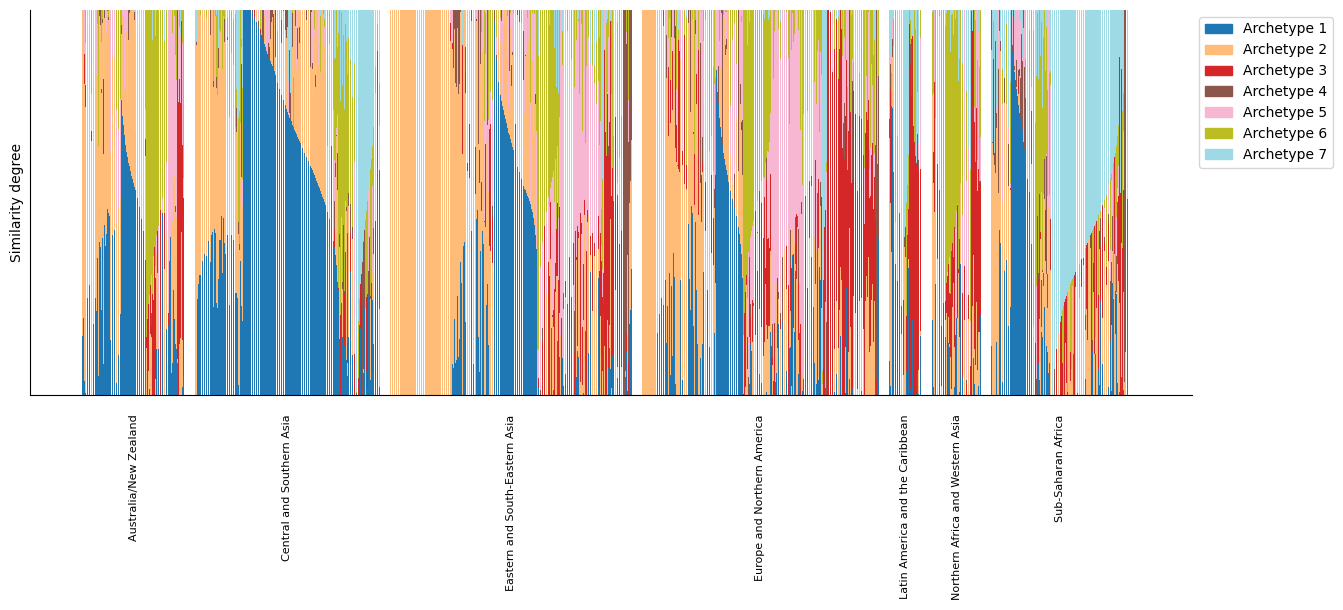

In [ ]:
vertices_labels = [f"Archetype {i+1}" for i in range(n_archs)]
filter_cols = ["region"]
metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

labels = metadata["region"].to_numpy()

stacked_bar(otu_aa.to_numpy(), vertices_labels=vertices_labels, labels=labels, perms= info["perms"], pad=0.01, figsize=(15,5))


<Axes: ylabel='Similarity degree'>

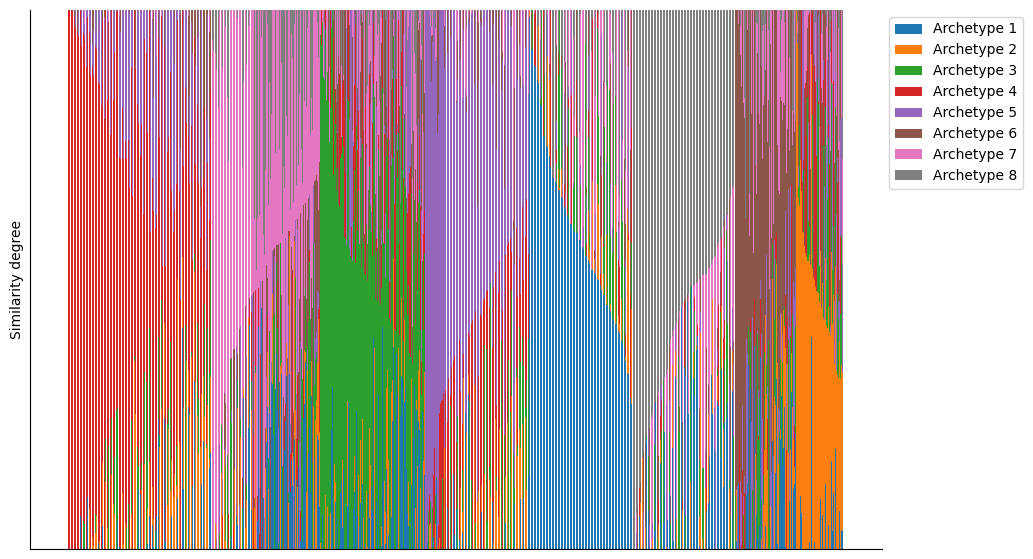

In [ ]:
# For Age Data: 
buckets = [(0,6), (6,12), (12,24), (24,36), (36,48), (48,60), (60, np.inf)]
vertices_labels = [f"Archetype {i+1}" for i in range(n_archs)]
filter_cols = ["age_months"]
metadata = extract_metadata_compendium(otu_aa_swapped.index, tags, meta, projects, filter_cols)

# For each metadata label, assign the bucket it belongs to
labels = metadata["age_months"].to_numpy()

# stacked_bar(otu_aa.to_numpy(), vertices_labels=vertices_labels, labels=labels, discretize=True, buckets=buckets, perms=info["perms"], pad=0.01, figsize=(11,5), cmap_name="tab20", alpha=0.8)
stacked_bar(otu_aa.to_numpy(), vertices_labels=vertices_labels, labels=None, perms= info["perms"], pad=0.01, figsize=(11,7), discretize=True, buckets=buckets)

## Random Forest Metadata

In [ ]:
dataDir = "datasets/tsv"

fName = r"results\Compendium_N3_N13_NoPC_NoGlom\Norm_pp_100iter_QC-Region7k\otu_AA_K6_1.0_None_jensenshannon.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}
n_archs = len(aa_archetypes)

projects = pd.read_csv("datasets/compendium/projects.csv", index_col=0)
meta = pd.read_table("datasets/compendium/sample_metadata.tsv", index_col=0)
tags = pd.read_table("datasets/compendium/tags.tsv")

reg_meta = extract_metadata_compendium(otu_aa.index, tags, meta, projects, ["region"])
# Export the metadata to a tsv file
reg_meta.to_csv("datasets/compendium/metadata/regionNk_QC_metadata.tsv", sep="\t")

## Hadza Dataset Formatting

### Heading Correction

In [ ]:
otu_file = r"datasets\tsv\hadza_otu_nov.tsv"
tax_file = r"datasets\tsv\hadza_tax_nov.tsv"
meta_file = r"datasets\tsv\hadza_sam_nov.tsv"

otu = pd.read_table(otu_file, index_col=0)
tax = pd.read_table(tax_file, index_col=0)
meta = pd.read_table(meta_file, index_col=0)

C:\Users\rayve\AppData\Local\Temp\ipykernel_36780\3082295036.py:7: DtypeWarning: Columns (1,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,57,58,61,65,66,67,68,69,70,71,72,73,75,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_table(meta_file, index_col=0)


In [ ]:
group = "Genus" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

# For each row, create a string of form "Phylum.Class.Order.Family.Genus"
def create_taxa_string(row):
    return ".".join([str(x) for x in row if x != "NA"])
taxa_string = tax.apply(create_taxa_string, axis=1)
col_names = taxa_string.unique()

grouped_cols = tax[group].unique()


otu_grouped = pd.DataFrame(index=otu.index, columns=col_names)

i = 0
for c in tqdm(otu.columns):
    grp_col = tax[group][c]
    matching_col = next((col for col in col_names if col.split(".")[-1] == grp_col), None)

    if(matching_col is not None): 
        if (pd.isnull(otu_grouped[matching_col]).all()):
            otu_grouped[matching_col] = otu[c]
            continue

        otu_grouped[matching_col] = otu_grouped[matching_col] + otu[c]
        # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

        i += 1
# Save the grouped otu table to a tsv file
out_path = f"datasets/tsv/hadza_otu_formatted.tsv"
otu_grouped.to_csv(out_path, sep="\t")

# Remove samples which are in meta but not in otu_grouped
# For indexes in hadza_sam that are nan, replace with SampleID2
newIndex = meta.index
newIndex = newIndex.where(newIndex.notnull(), meta["SampleID2"])
meta.index = newIndex
meta = meta[meta.index.isin(otu_grouped.index)]

100%|██████████| 2647/2647 [00:00<00:00, 3990.04it/s]


### Hadza Data Normalization

In [ ]:
otu_file = r"datasets\tsv\hadza_otu_formatted.tsv"
meta_file = r"datasets\tsv\hadza_meta_formatted.tsv"

otu = pd.read_table(otu_file, index_col=0)
meta = pd.read_table(meta_file, index_col=0)

In [ ]:
control = {}  # Control for normalization
normalize = {"location": None}  # Normalize by sample type
ignore = ["Nigeria (Bassa)", "Nigeria (Urban)", "NA", "unknown"]  

saveDir = "datasets/tsv/normalized"  # Directory to save the normalized data
saveName = "hadza_otu_normalized_region.csv"

norm_otu, norm_meta = normalize_data(
    control=control,
    normalize=normalize,
    otu=otu_grouped,
    meta=meta,
    tags=pd.DataFrame(),
    projects=pd.DataFrame(),
    saveDir=None,
    saveName=None,
    ignore=ignore,
    tol=10,  # Adjust tol as needed
    verbose=True
)
norm_otu = quality_control(norm_otu, saveDir=saveDir, saveName=saveName, verbose=True, min_taxa_level=6, min_nonzero_samples=0.001, min_counts=5000)

Number of samples before control Normalization: 17332
Number of samples after control filtering: 17332
Value Nigeria (Bassa) ignored
Value Nigeria (Urban) ignored
Minimum counts: 106 for value Tanzania (Hadza) in location
Ignored 2 values

                  location
Tanzania (Hadza)       106
Bangladesh            1166
South Africa           148
Peru                   481
India                  331
Brazil                 124
Nigeria (Bassa)          0
Nigeria (Urban)          0
Malawi                1166
Sweden                1166
Germany               1037
Finland               1166
Washington             815
Colorado              1166
Georgia                591

Normalized Data shape:  (9463, 311)
Starting quality control on OTU table...
Initial OTU table shape: (9463, 311)
Removed 35 samples with total counts less than 5000
Removed 40 columns with unknown Species
Removed 14 columns with non-zero values in less than 0.1% samples (9 samples)
Filtered OTU table shape: (9428, 257)
Saved

In [ ]:
control = {"location": ["Sweden", "Finland", "Colorado", "Washington", "Germany", "Georgia"]}  # Control for normalization
age_buckets = [(0,3), (3,6), (6,12), (12,24), (24,36), (36,48), (48,60), (60, np.inf)]
normalize = {"age_months": age_buckets}  # Normalize by age
ignore = ["NA", "unknown"]  

saveDir = "datasets/tsv/normalized"  # Directory to save the normalized data
saveName = "hadza_otu_normalized_age.csv"

norm_otu, norm_meta = normalize_data(
    control=control,
    normalize=normalize,
    otu=otu_grouped,
    continuous=True,
    meta=meta,
    tags=pd.DataFrame(),
    projects=pd.DataFrame(),
    saveDir=None,
    saveName=None,
    ignore=ignore,
    tol=10,  # Adjust tol as needed
    verbose=True
)
norm_otu = quality_control(norm_otu, saveDir=saveDir, saveName=saveName, verbose=True, min_taxa_level=6, min_nonzero_samples=0.001, min_counts=5000)

Number of samples before control Normalization: 17332
Number of samples after control filtering: 10905
Minimum counts: 17 for value (60, inf) in age_months
Ignored 0 values

         age_months
0  3.0           33
3  6.0          187
6  12.0         187
12 24.0         187
24 36.0         187
36 48.0         187
48 60.0          48
60 inf           17

Normalized Data shape:  (1033, 311)
Starting quality control on OTU table...
Initial OTU table shape: (1033, 311)
Removed 0 samples with total counts less than 5000
Removed 40 columns with unknown Species
Removed 48 columns with non-zero values in less than 0.1% samples (1 samples)
Filtered OTU table shape: (1033, 223)
Saved filtered data to hadza_otu_normalized_age.csv


In [ ]:
test_metadata = extract_metadata_compendium(otu.index, pd.DataFrame(), meta, pd.DataFrame(), ["location", "age_months"])

# Count the number of samples in each location and age bucket
location_counts = test_metadata["location"].value_counts()
age_counts = test_metadata["age_months"].value_counts()

# Print the counts
print("Location counts:")
print(location_counts)
print("\nAge bucket counts:")
print(age_counts)

Location counts:
location
Sweden              3814
Malawi              2738
Finland             2717
Bangladesh          2273
Colorado            1931
Germany             1037
Washington           815
Georgia              591
Peru                 481
India                331
South Africa         148
Brazil               124
Tanzania (Hadza)     106
Nigeria (Urban)       13
Nigeria (Bassa)        9
Name: count, dtype: int64

Age bucket counts:
age_months
12.000000    677
18.000000    658
30.000000    587
6.000000     582
1.000000     381
            ... 
37.700000      1
66.168378      1
15.540041      1
57.500000      1
30.817248      1
Name: count, Length: 1835, dtype: int64
